# Goal - Predict hosptal readmission

1. Univariate, non-visual
   - shape, dtypes
   - info
   - missingness
   - duplicates
   - describe()
   - value_counts()
   - cardinality
   - distributions summarized numerically
2. Bivariate, non-visual
   - each predictor vs target
   - groupby() rates
   - correlations for numeric variables
   - crosstabs
   - maybe simple statistical tests later
3. Univariate / bivariate visual
   - histograms
   - boxplots
   - count plots
   - bar charts of readmission rate
   - numeric feature vs readmission plots
4. Multivariate, non-visual
   - correlation matrix
   - grouped/cross-tab analyses involving multiple predictors
   - interactions like number_inpatient × age
   - perhaps pivot tables
   - checking whether an apparent bivariate relationship persists after stratifying on another variable
5. Multivariate visual
   - heatmaps
   - scatterplots with hue
   - grouped/stacked bars
   - interaction plots
   - maybe pairplots selectively, not on 50 columns
   

1. Data Overview & Cleaning
2. Univariate Non-Visual EDA
3. Bivariate Non-Visual EDA
4. Univariate/Bivariate Visual EDA
5. Multivariate EDA
6. Feature Engineering
7. Modeling

1. Data Loading and Initial Inspection

2. Data Cleaning

3. Univariate Non-Visual EDA

4. Bivariate Non-Visual EDA

5. Visual EDA

6. Multivariate EDA

7. Feature Engineering
 8. Modeling

----------------------------------------------------

## 1. Data Loading and Cleaning

In [1]:
import os
import numpy as np
import pandas as pd
import missingno as msno

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
os.listdir()

['.git',
 '.gitignore',
 '.venv',
 '01_eda.ipynb',
 '01_eda_organized.ipynb',
 'data',
 'readmission_eda.html']

In [3]:

DATA_PATH = 'C:/Users/dave_/Desktop/projects/hospital readmission/data/'
DATA_FILE = 'diabetic_data.csv'
df = pd.read_csv(DATA_PATH + DATA_FILE)

In [4]:
df.shape

(101766, 50)

In [5]:
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [7]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [8]:
df.dtypes

encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

In [9]:
df['readmitted'].value_counts()

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

In [10]:
df['readmitted'].value_counts(normalize=True)

readmitted
NO     0.539119
>30    0.349282
<30    0.111599
Name: proportion, dtype: float64

In [11]:
print(df.isnull().sum())

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [12]:
(df == "?").sum().sort_values(ascending=False)

weight                      98569
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
admission_type_id               0
patient_nbr                     0
encounter_id                    0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
number_outpatient               0
number_diagnoses                0
max_glu_serum                   0
A1Cresult                       0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

<Axes: >

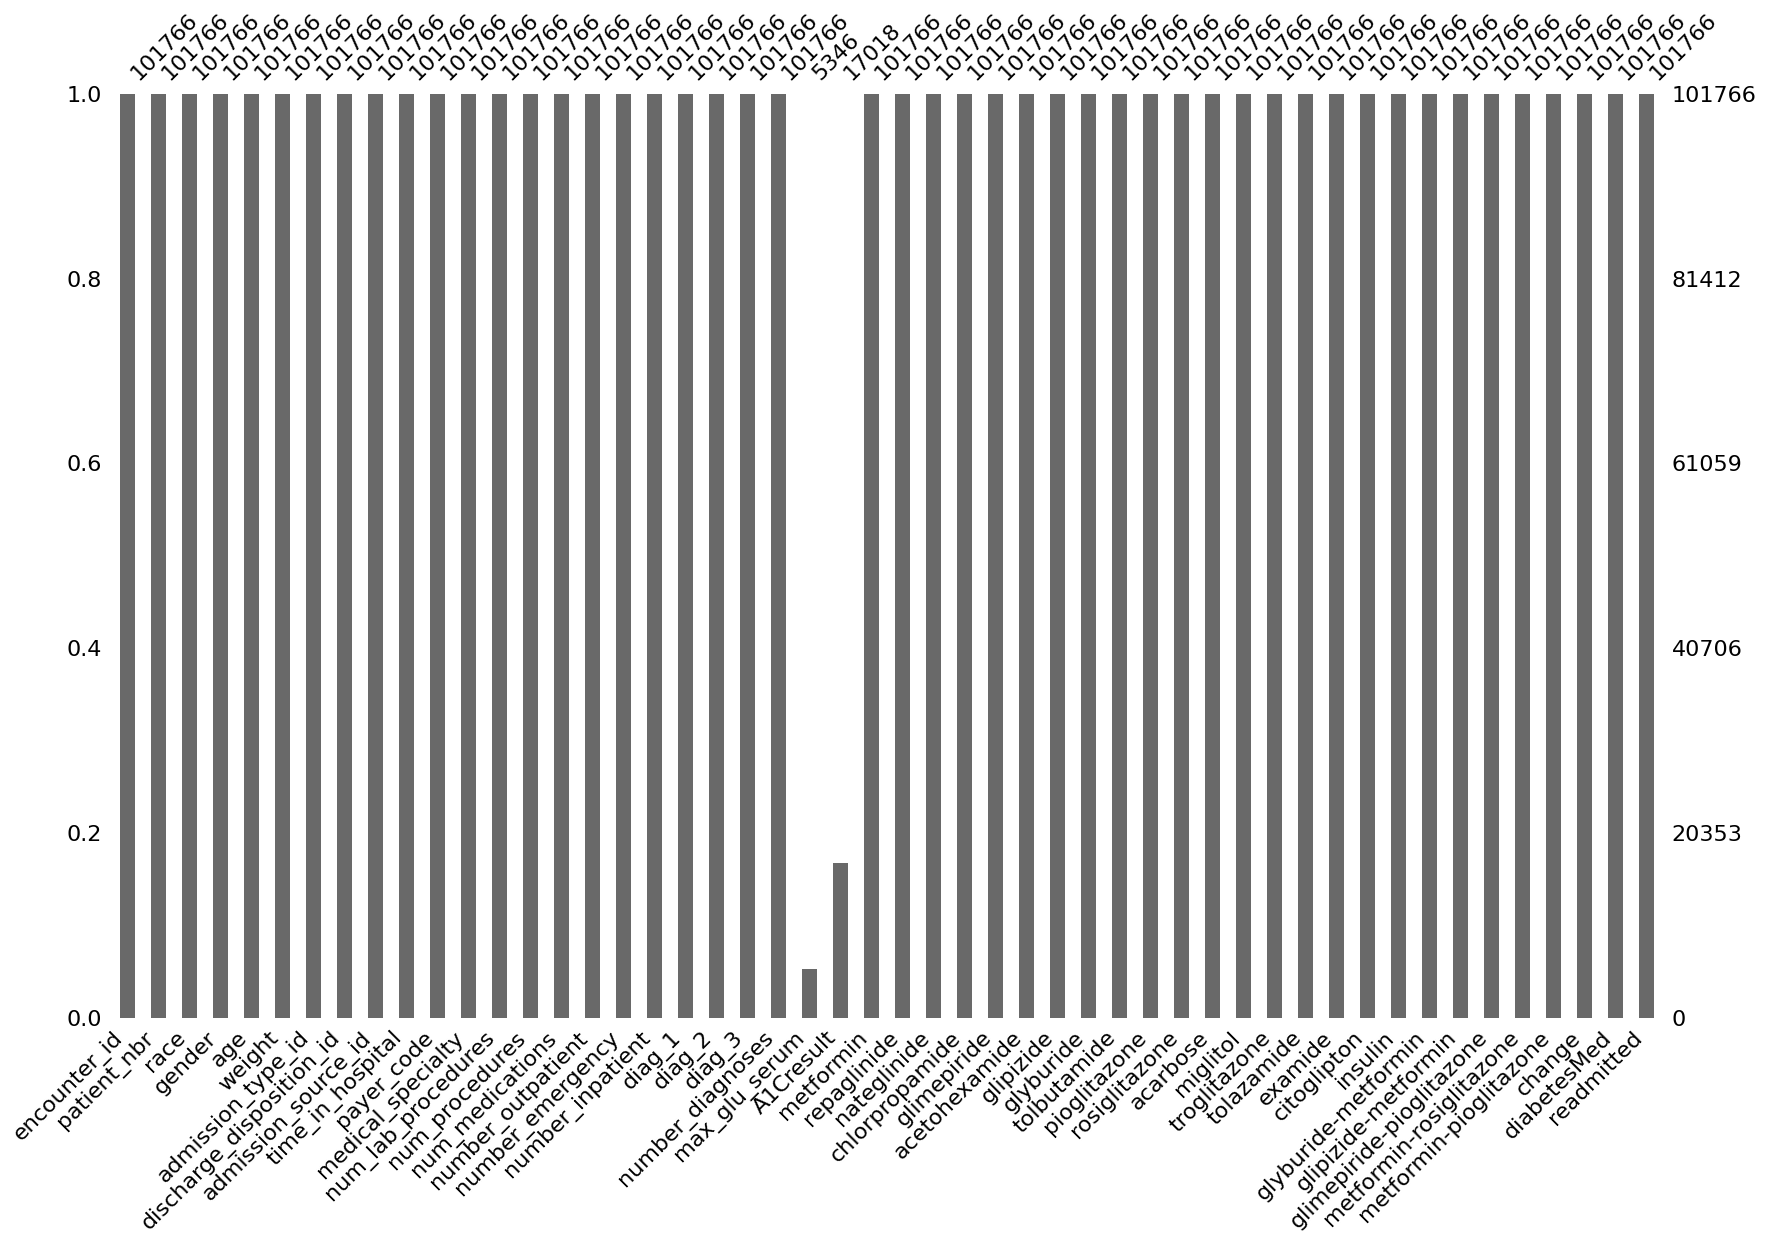

In [13]:
msno.bar(df, figsize=(20,12))

<Axes: >

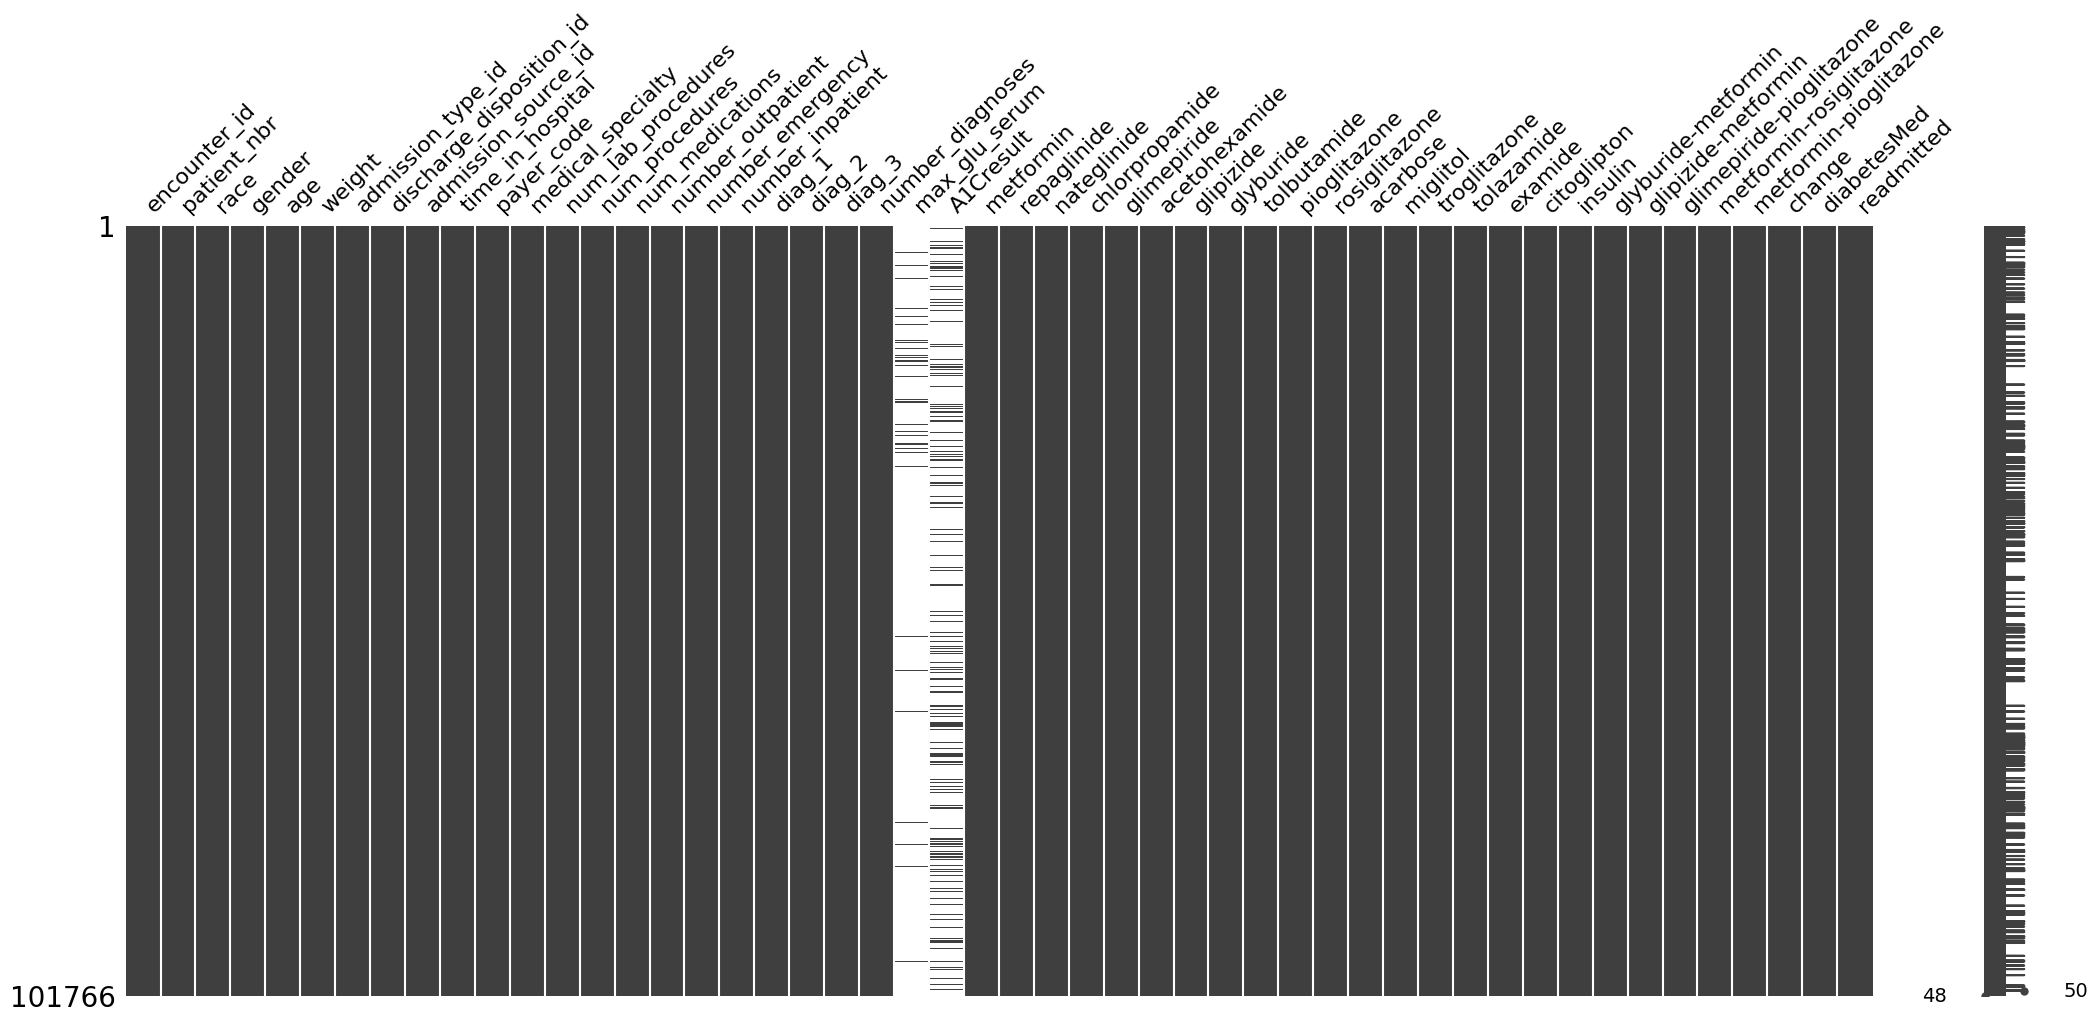

In [14]:
msno.matrix(df)

<Axes: >

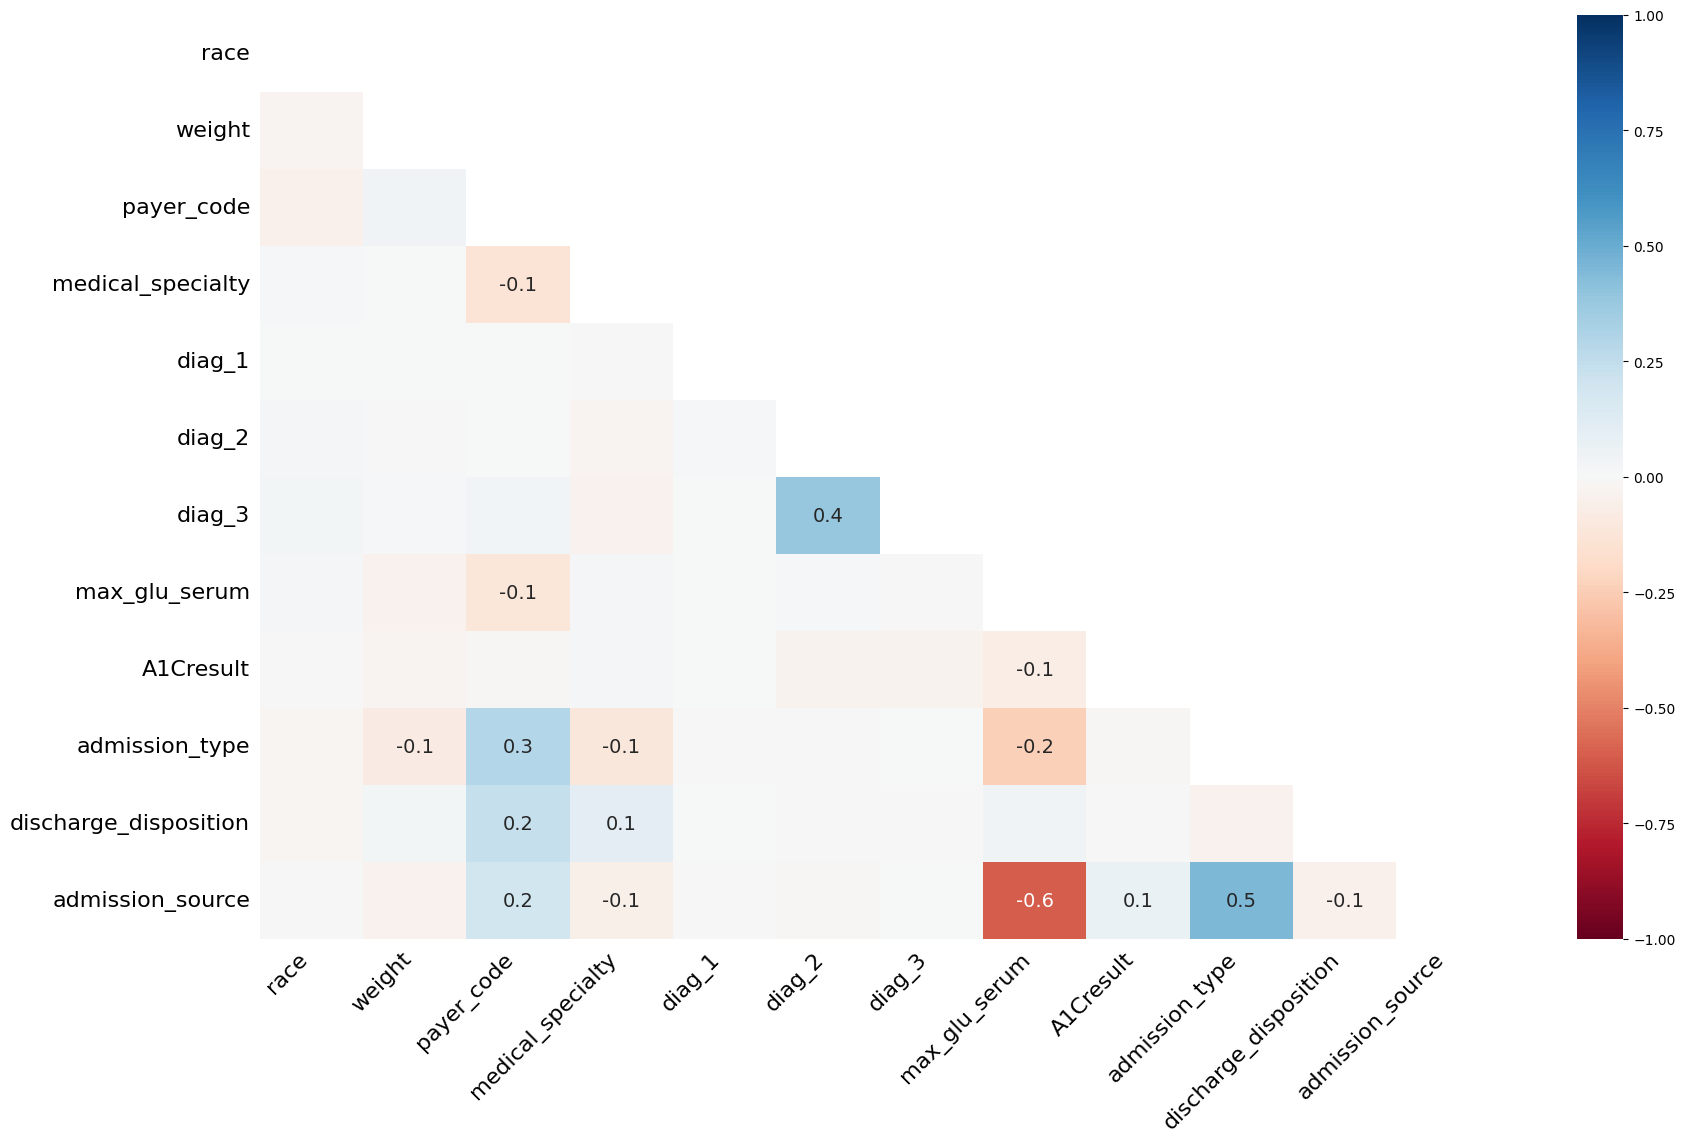

In [102]:
msno.heatmap(df)

<Axes: >

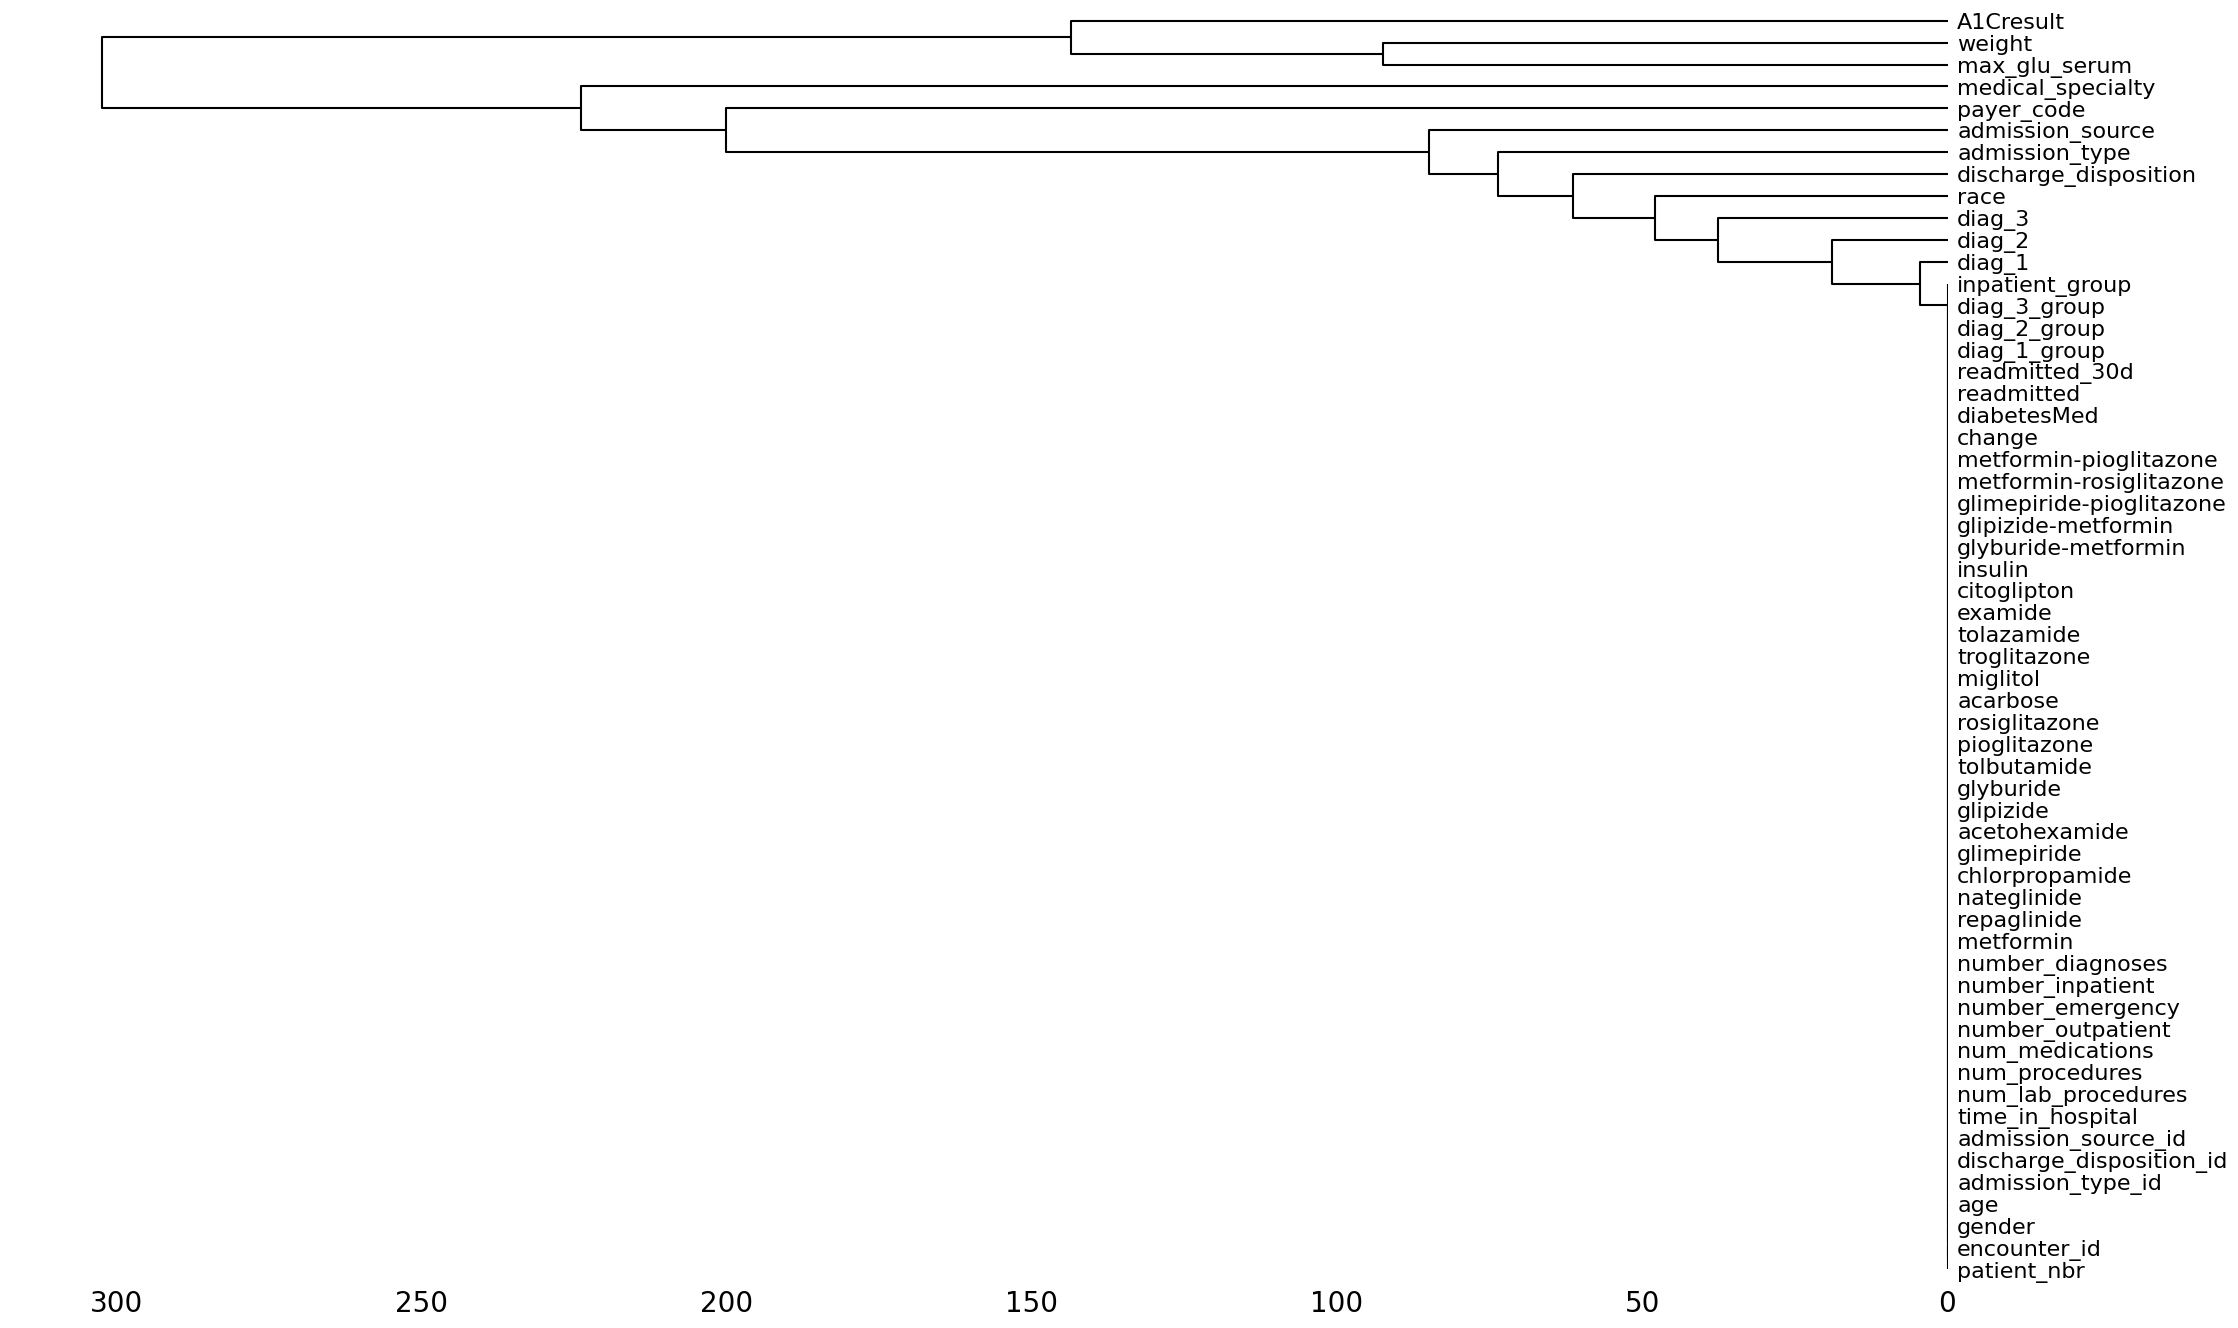

In [103]:
msno.dendrogram(df)

In [17]:
df = df.replace('?', np.nan)

In [18]:
df.isna().sum().sort_values(ascending=False)

weight                      98569
max_glu_serum               96420
A1Cresult                   84748
medical_specialty           49949
payer_code                  40256
race                         2273
diag_3                       1423
diag_2                        358
diag_1                         21
patient_nbr                     0
time_in_hospital                0
admission_source_id             0
num_lab_procedures              0
encounter_id                    0
admission_type_id               0
discharge_disposition_id        0
gender                          0
age                             0
number_inpatient                0
number_emergency                0
number_outpatient               0
num_medications                 0
num_procedures                  0
number_diagnoses                0
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

### Create target variable

In [19]:
df['readmitted_30d'] = (df['readmitted'] == "<30").astype(int)

### Variable mapping and diagnosis grouping


In [20]:
mapping = pd.read_csv('data/IDS_mapping.csv')
mapping

,admission_type_id,description
0,1,Emergency
1,2,Urgent
2,3,Elective
3,4,Newborn
4,5,Not Available
...,...,...
62,22,Transfer from hospital inpt/same fac reslt in...
63,23,Born inside this hospital
64,24,Born outside this hospital
65,25,Transfer from Ambulatory Surgery Center


In [21]:
mapping.iloc[39]

admission_type_id                                                   29
description          Discharged/transferred to a Critical Access Ho...
Name: 39, dtype: object

In [22]:
admission_type_map = dict(
    zip(
        mapping.loc[0:7, 'admission_type_id'].astype(int),
        mapping.loc[0:7, 'description']
    )
)
admission_type_map

{1: 'Emergency',
 2: 'Urgent',
 3: 'Elective',
 4: 'Newborn',
 5: 'Not Available',
 6: nan,
 7: 'Trauma Center',
 8: 'Not Mapped'}

In [23]:
df['admission_type'] = df['admission_type_id'].map(admission_type_map)

In [24]:
mapping.iloc[9:40]

,admission_type_id,description
9,discharge_disposition_id,description
10,1,Discharged to home
11,2,Discharged/transferred to another short term h...
12,3,Discharged/transferred to SNF
13,4,Discharged/transferred to ICF
14,5,Discharged/transferred to another type of inpa...
15,6,Discharged/transferred to home with home healt...
16,7,Left AMA
17,8,Discharged/transferred to home under care of H...
18,9,Admitted as an inpatient to this hospital


In [25]:
discharge_map = dict(
    zip(
        mapping.loc[10:39, "admission_type_id"].astype(int),
        mapping.loc[10:39, "description"]
    )
)

In [26]:
df['discharge_disposition'] = df['discharge_disposition_id'].map(discharge_map)

In [27]:
admission_source_map = dict(
    zip(
        mapping.loc[42:49, "admission_type_id"].astype(int),
        mapping.loc[42:49, "description"]
    )
)

In [28]:
df['admission_source'] = df['admission_source_id'].map(admission_source_map)


In [29]:
def diag_group(code):
    if pd.isna(code):
        return "Unknown"

    code = str(code)

    if code.startswith('250'):
        return "Diabetes"

    try:
        num = float(code)

        if 390 <= num <459 or num == 785:
            return "Circulatory"
        elif 460 <= num <= 519 or num == 786:
            return "Respiratory"
        elif 520 <= num <= 579 or num == 787:
            return "Digestive"
        elif 580 <= num <= 629 or num == 788:
            return "Genitourinary"
        elif 710 <= num <= 739: 
            return "Musculoskeltal"
        elif 800 <= num <= 999:
            return "Injury"
        elif 140 <= num <= 239:
            return "Neoplasm" 
        else:
            return "Other"     

    except ValueError:
        return "Other"  
    

In [30]:
for col in ['diag_1', 'diag_2', 'diag_3']:
    df[f'{col}_group'] = df[col].apply(diag_group)

-------------------------------------

## 2. Univariate Non-Visual EDA


In [31]:
df.age.value_counts().sort_index()

age
[0-10)        161
[10-20)       691
[20-30)      1657
[30-40)      3775
[40-50)      9685
[50-60)     17256
[60-70)     22483
[70-80)     26068
[80-90)     17197
[90-100)     2793
Name: count, dtype: int64

In [32]:
display(df['readmitted_30d'].value_counts())
display(df['readmitted_30d'].value_counts(normalize=True))


readmitted_30d
0    90409
1    11357
Name: count, dtype: int64

readmitted_30d
0    0.888401
1    0.111599
Name: proportion, dtype: float64

In [33]:
for diag_code in ['diag_1', 'diag_2', 'diag_3']:
    display(df[diag_code].value_counts().head(20))

diag_1
428      6862
414      6581
786      4016
410      3614
486      3508
427      2766
491      2275
715      2151
682      2042
434      2028
780      2019
996      1967
276      1889
38       1688
250.8    1680
599      1595
584      1520
V57      1207
250.6    1183
518      1115
Name: count, dtype: int64

diag_2
276       6752
428       6662
250       6071
427       5036
401       3736
496       3305
599       3288
403       2823
414       2650
411       2566
250.02    2074
707       1999
585       1871
584       1649
491       1545
250.01    1523
285       1520
780       1491
425       1434
682       1433
Name: count, dtype: int64

diag_3
250       11555
401        8289
276        5175
428        4577
427        3955
414        3664
496        2605
403        2357
585        1992
272        1969
599        1941
V45        1389
250.02     1369
707        1360
780        1334
285        1200
425        1136
250.6      1080
424        1063
584         963
Name: count, dtype: int64

In [34]:
for col in ['diag_1_group', 'diag_2_group', 'diag_3_group']:
    print(f'\n### {col}')
    display(df[col].value_counts())


### diag_1_group


diag_1_group
Circulatory       30340
Other             18269
Respiratory       14423
Digestive          9475
Diabetes           8757
Injury             6974
Genitourinary      5117
Musculoskeltal     4957
Neoplasm           3433
Unknown              21
Name: count, dtype: int64


### diag_2_group


diag_2_group
Circulatory       31828
Other             26606
Diabetes          12794
Respiratory       10895
Genitourinary      8376
Digestive          4170
Neoplasm           2547
Injury             2428
Musculoskeltal     1764
Unknown             358
Name: count, dtype: int64


### diag_3_group


diag_3_group
Circulatory       30202
Other             29299
Diabetes          17157
Respiratory        7358
Genitourinary      6680
Digestive          3930
Injury             1946
Musculoskeltal     1915
Neoplasm           1856
Unknown            1423
Name: count, dtype: int64

------------------------------------------------

## 3. Bivariate Non-Visual EDA


In [35]:
(df.groupby('age')['readmitted_30d'].mean() * 100).round(2)

age
[0-10)       1.86
[10-20)      5.79
[20-30)     14.24
[30-40)     11.23
[40-50)     10.60
[50-60)      9.67
[60-70)     11.13
[70-80)     11.77
[80-90)     12.08
[90-100)    11.10
Name: readmitted_30d, dtype: float64

In [36]:
(df.groupby('gender')['readmitted_30d'].mean() * 100).round(2)

gender
Female             11.25
Male               11.06
Unknown/Invalid     0.00
Name: readmitted_30d, dtype: float64

In [37]:
(df.groupby('time_in_hospital')['readmitted_30d'].mean() * 100).round(2)

time_in_hospital
1      8.18
2      9.94
3     10.67
4     11.81
5     12.03
6     12.59
7     12.83
8     14.23
9     13.72
10    14.35
11    10.51
12    13.33
13    12.31
14    12.96
Name: readmitted_30d, dtype: float64

In [38]:
(df.groupby('number_inpatient')['readmitted_30d'].mean() * 100).round(2)

number_inpatient
0       8.44
1      12.92
2      17.43
3      20.29
4      23.61
5      31.40
6      34.58
7      35.45
8      44.37
9      42.34
10     42.62
11     67.35
12     50.00
13     50.00
14     40.00
15    100.00
16     33.33
17    100.00
18      0.00
19     50.00
21    100.00
Name: readmitted_30d, dtype: float64

In [39]:
summary = df.groupby('number_inpatient')['readmitted_30d'].agg(['mean', 'count'])
summary['mean'] = (summary['mean'] * 100).round(2)
summary = summary.sort_values('mean',ascending=True)
summary

,mean,count
number_inpatient,,
18,0.00,1
0,8.44,67630
1,12.92,19521
2,17.43,7566
3,20.29,3411
4,23.61,1622
5,31.40,812
16,33.33,6
6,34.58,480


In [40]:
summary = df.groupby('age')['readmitted_30d'].agg(['mean','count'])
summary['mean'] = summary['mean'] * 100
summary

,mean,count
age,,
[0-10),1.863354,161
[10-20),5.788712,691
[20-30),14.242607,1657
[30-40),11.231788,3775
[40-50),10.604027,9685
[50-60),9.666203,17256
[60-70),11.128408,22483
[70-80),11.773055,26068
[80-90),12.083503,17197


In [41]:
var_list = ['time_in_hospital', 'number_emergency', 'number_outpatient', 'number_diagnoses']
for var in var_list:
    print(f'\n### {var}')
    summary = df.groupby(var)['readmitted_30d'].agg(['mean','count'])
    summary['mean'] = (summary['mean'] * 100).round(2)
    display(summary)


### time_in_hospital


,mean,count
time_in_hospital,,
1,8.18,14208
2,9.94,17224
3,10.67,17756
4,11.81,13924
5,12.03,9966
6,12.59,7539
7,12.83,5859
8,14.23,4391
9,13.72,3002



### number_emergency


,mean,count
number_emergency,,
0,10.47,90383
1,14.35,7677
2,18.27,2042
3,20.28,725
4,30.75,374
5,24.48,192
6,23.40,94
7,26.03,73
8,32.00,50



### number_outpatient


,mean,count
number_outpatient,,
0,10.67,85027
1,13.92,8547
2,13.75,3594
3,12.29,2042
4,15.10,1099
5,11.82,533
6,13.20,303
7,15.48,155
8,5.10,98



### number_diagnoses


,mean,count
number_diagnoses,,
1,5.94,219
2,6.06,1023
3,7.37,2835
4,8.25,5537
5,9.15,11393
6,10.41,10161
7,10.77,10393
8,11.81,10616
9,12.38,49474


In [42]:
cat_vars = [
    'admission_type_id',
    'discharge_disposition_id',
    'admission_source_id',
    'race',
    'gender'    
]

for var in cat_vars:
    print(f'\n### {var}')
    summary = (
        df.groupby(var)['readmitted_30d']
        .agg(['mean', 'count'])
    )
    summary['mean'] = summary['mean'] * 100
    display(summary)


### admission_type_id


,mean,count
admission_type_id,,
1,11.522504,53990
2,11.179654,18480
3,10.392708,18869
4,10.000000,10
5,10.344828,4785
6,11.075411,5291
7,0.000000,21
8,8.437500,320



### discharge_disposition_id


,mean,count
discharge_disposition_id,,
1,9.300395,60234
2,16.071429,2128
3,14.662462,13954
4,12.760736,815
5,20.861486,1184
6,12.695706,12902
7,14.446228,623
8,13.888889,108
9,42.857143,21



### admission_source_id


,mean,count
admission_source_id,,
1,10.586843,29565
2,10.054348,1104
3,15.508021,187
4,9.695639,3187
5,11.812865,855
6,9.363958,2264
7,11.688176,57494
8,12.500000,16
9,10.400000,125



### race


,mean,count
race,,
AfricanAmerican,11.218116,19210
Asian,10.140406,641
Caucasian,11.290556,76099
Hispanic,10.407462,2037
Other,9.628154,1506



### gender


,mean,count
gender,,
Female,11.245156,54708
Male,11.061524,47055
Unknown/Invalid,0.000000,3


In [43]:
df.groupby('admission_type')['readmitted_30d'].agg(['mean', 'count'])

,mean,count
admission_type,,
Elective,0.103927,18869
Emergency,0.115225,53990
Newborn,0.100000,10
Not Available,0.103448,4785
Not Mapped,0.084375,320
Trauma Center,0.000000,21
Urgent,0.111797,18480


In [44]:
cat_vars = [
    "admission_type",
    "discharge_disposition",
    "admission_source",
    "race",
    "gender"
]

for var in cat_vars:
    print(f'\n### {var}')
    summary = (
        df.groupby(var)['readmitted_30d']
        .agg(['mean', 'count'])
        .sort_values('mean', ascending=False)
    )
    summary['mean'] = summary['mean'] * 100
    display(summary)


### admission_type


,mean,count
admission_type,,
Emergency,11.522504,53990
Urgent,11.179654,18480
Elective,10.392708,18869
Not Available,10.344828,4785
Newborn,10.000000,10
Not Mapped,8.437500,320
Trauma Center,0.000000,21



### discharge_disposition


,mean,count
discharge_disposition,,
Still patient or expected to return for outpatient services,66.666667,3
Discharged/transferred within this institution to Medicare approved swing bed,44.444444,63
Admitted as an inpatient to this hospital,42.857143,21
Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital,36.690647,139
Discharged/transferred to another rehab fac including rehab units of a hospital .,27.696939,1993
Discharged/transferred to another type of inpatient care institution,20.861486,1184
Discharged/transferred to another short term hospital,16.071429,2128
Discharged/transferred to SNF,14.662462,13954
Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare.,14.583333,48



### admission_source


,mean,count
admission_source,,
HMO Referral,15.508021,187
Court/Law Enforcement,12.500000,16
Transfer from a Skilled Nursing Facility (SNF),11.812865,855
Emergency Room,11.688176,57494
Physician Referral,10.586843,29565
Clinic Referral,10.054348,1104
Transfer from a hospital,9.695639,3187
Transfer from another health care facility,9.363958,2264



### race


,mean,count
race,,
Caucasian,11.290556,76099
AfricanAmerican,11.218116,19210
Hispanic,10.407462,2037
Asian,10.140406,641
Other,9.628154,1506



### gender


,mean,count
gender,,
Female,11.245156,54708
Male,11.061524,47055
Unknown/Invalid,0.000000,3


In [45]:
cat_vars_2 = [
    "A1Cresult",
    "max_glu_serum",
    "change",
    "diabetesMed",
    "insulin"
]

for var in cat_vars_2:
    print(f'\n### {var}')
    summary = (
        df.groupby(var)['readmitted_30d']
        .agg(['mean', 'count'])
        .sort_values('mean', ascending=False)
    )
    summary['mean'] = summary['mean'] * 100
    display(summary)


### A1Cresult


,mean,count
A1Cresult,,
>7,10.047219,3812
>8,9.870983,8216
Norm,9.659319,4990



### max_glu_serum


,mean,count
max_glu_serum,,
>300,14.319620,1264
>200,12.457912,1485
Norm,11.359261,2597



### change


,mean,count
change,,
Ch,11.822765,47011
No,10.590814,54755



### diabetesMed


,mean,count
diabetesMed,,
Yes,11.626661,78363
No,9.597060,23403



### insulin


,mean,count
insulin,,
Down,13.897528,12218
Up,12.990456,11316
Steady,11.128400,30849
No,10.037355,47383


In [46]:
df.groupby('insulin')['readmitted_30d'].agg(['mean', 'count'])

,mean,count
insulin,,
Down,0.138975,12218
No,0.100374,47383
Steady,0.111284,30849
Up,0.129905,11316


In [47]:
for col in ['diag_1_group', 'diag_2_group', 'diag_3_group']:
    print(f'\n###{col}')
    summary = df.groupby(col)['readmitted_30d'].agg(['mean', 'count'])
    summary['mean'] = summary['mean'] * 100
    display(summary.sort_values('mean', ascending=False))


###diag_1_group


,mean,count
diag_1_group,,
Unknown,23.809524,21
Diabetes,12.983899,8757
Injury,12.245483,6974
Other,11.462040,18269
Circulatory,11.460119,30340
Genitourinary,10.846199,5117
Digestive,10.712401,9475
Neoplasm,10.078648,3433
Respiratory,9.727519,14423



###diag_2_group


,mean,count
diag_2_group,,
Neoplasm,14.919513,2547
Genitourinary,11.759790,8376
Digestive,11.486811,4170
Injury,11.449753,2428
Other,11.253101,26606
Circulatory,11.106573,31828
Diabetes,10.583086,12794
Respiratory,10.518587,10895
Musculoskeltal,10.034014,1764



###diag_3_group


,mean,count
diag_3_group,,
Neoplasm,14.224138,1856
Genitourinary,13.458084,6680
Respiratory,12.054906,7358
Digestive,11.959288,3930
Injury,11.562179,1946
Other,11.065224,29299
Circulatory,10.800609,30202
Musculoskeltal,10.652742,1915
Diabetes,10.567115,17157


So far, our strongest candidates appear to be:
- number_inpatient
- number_emergency
- time_in_hospital
- number_diagnoses
- discharge_disposition
- insulin status
- diagnosis groups

--------------------------------------

## 4. Univariate Visual EDA


In [48]:
# get list of numeric vars
num_vars = df.select_dtypes(include=["number"]).columns.tolist()

In [49]:
num_vars


['encounter_id',
 'patient_nbr',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses',
 'readmitted_30d']

In [50]:
# remove unneeded vars

num_vars = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

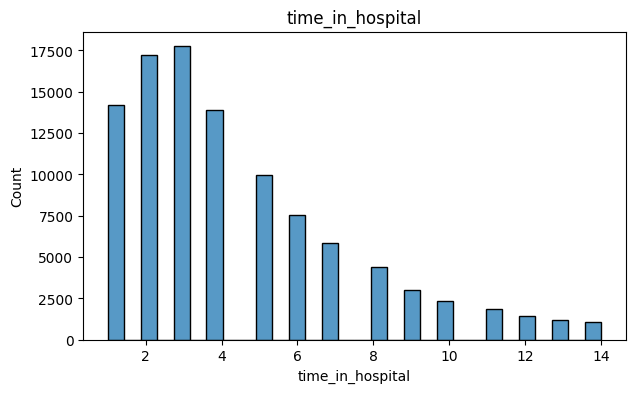

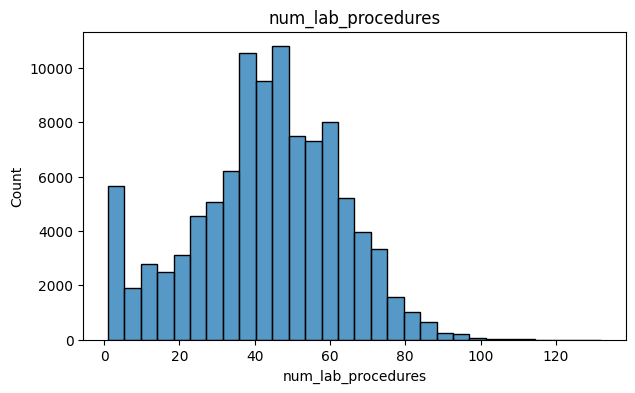

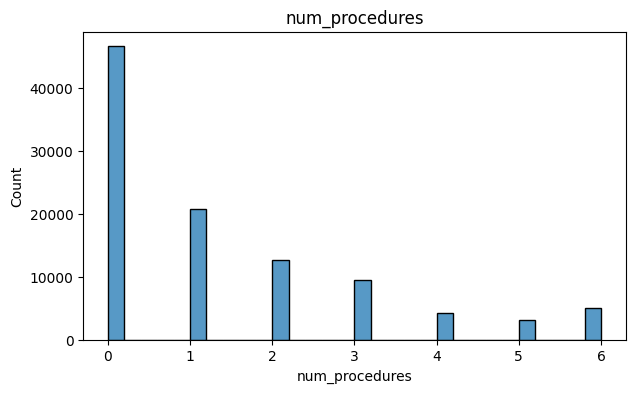

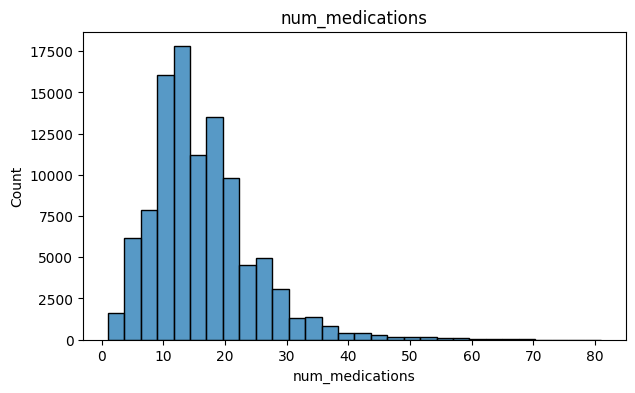

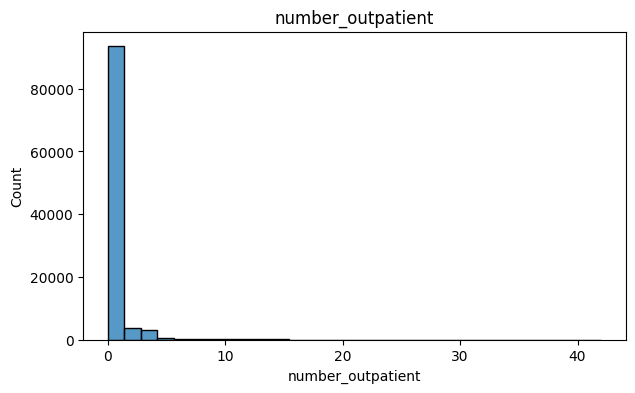

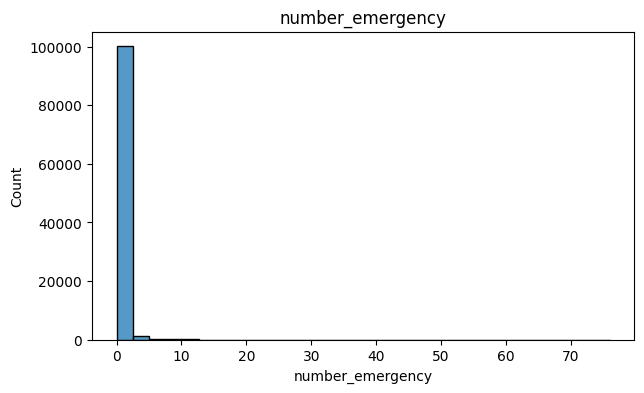

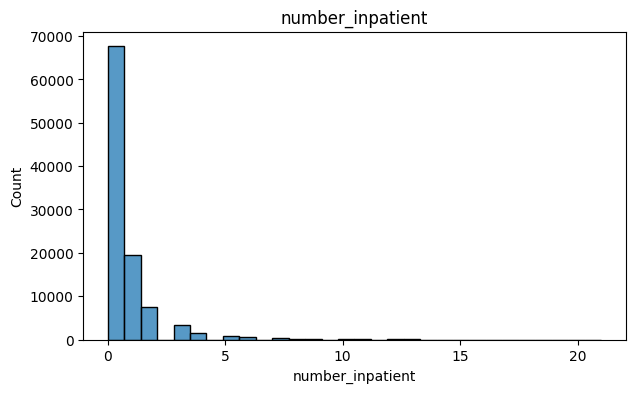

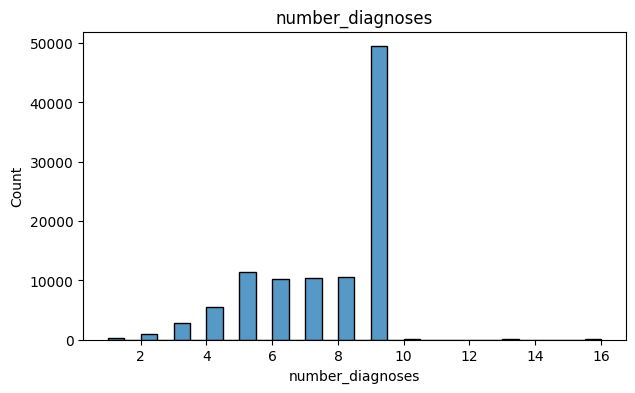

In [51]:
for var in num_vars:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=var, bins=30)
    plt.title(var)
    plt.show()


- time_in_hospital: right-skewed, most stays are short, with counts tapering off as LOS increases.
- num_lab_procedures: roughly unimodal around the 40–50 range, with a long right tail and a noticeable spike near zero.
- num_procedures: strongly discrete and right-skewed; most encounters have 0–2 procedures.
- num_medications: right-skewed, concentrated roughly around 10–20 meds, with a long tail.
- number_outpatient: extremely zero-inflated; almost everyone has 0 prior outpatient visits.
- number_inpatient: also heavily zero-inflated, though less extreme than outpatient.
- number_diagnoses: very discrete, with a huge spike at 9 diagnoses.

number_diagnoses shows an unusual concentration at 9 diagnoses. The official dataset documentation defines the variable as the number of diagnoses entered into the system but does not explain the spike. This likely reflects a structural or administrative feature of the source data rather than a natural clinical distribution, so the variable should be interpreted cautiously.

In [52]:
#get categorical vars
# get list of numeric vars
cat_vars = df.select_dtypes(include=["object"]).columns.tolist()


In [53]:
cat_vars

['race',
 'gender',
 'age',
 'weight',
 'payer_code',
 'medical_specialty',
 'diag_1',
 'diag_2',
 'diag_3',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted',
 'admission_type',
 'discharge_disposition',
 'admission_source',
 'diag_1_group',
 'diag_2_group',
 'diag_3_group']

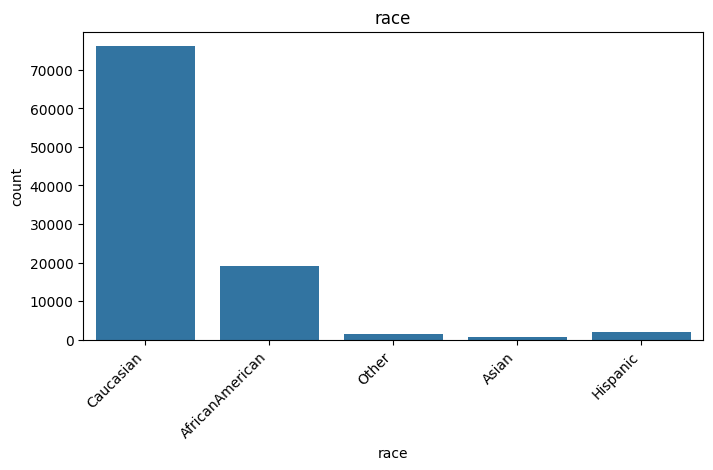

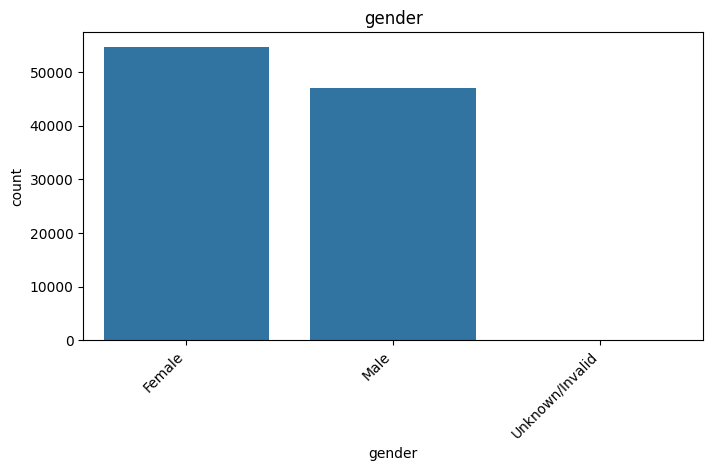

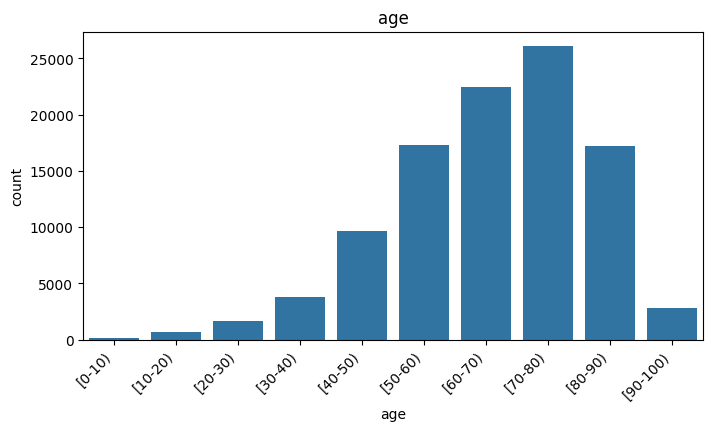

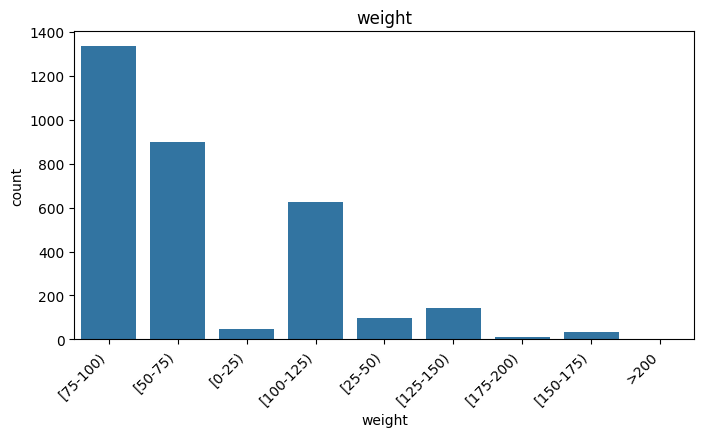

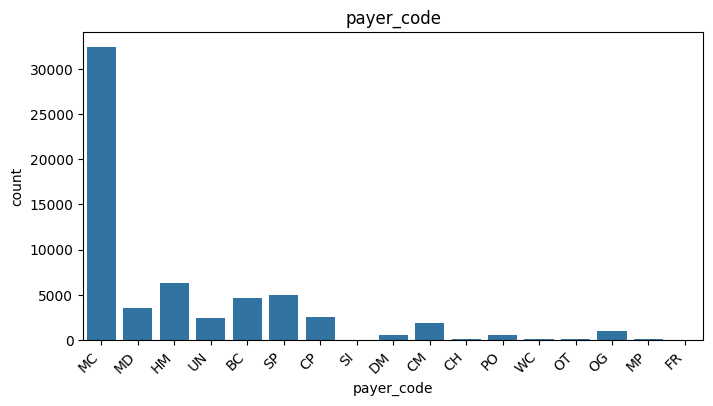

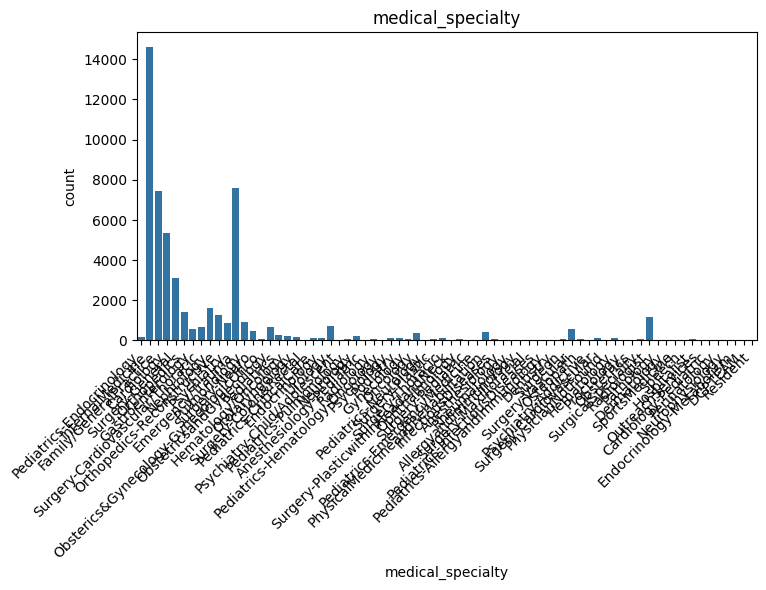

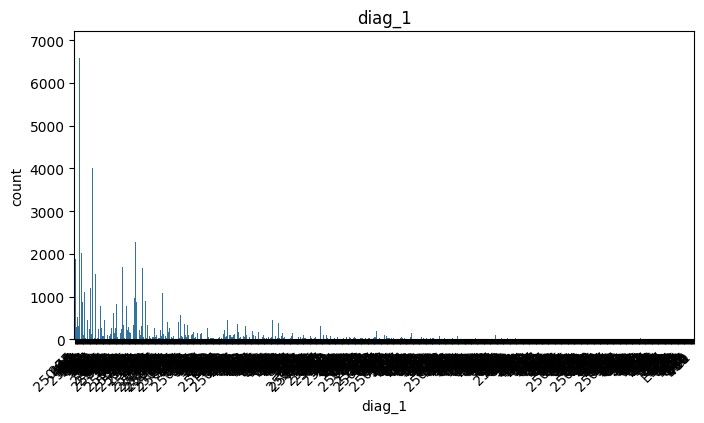

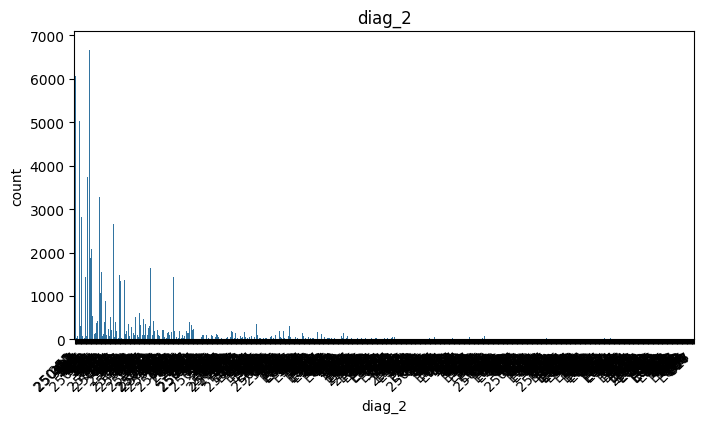

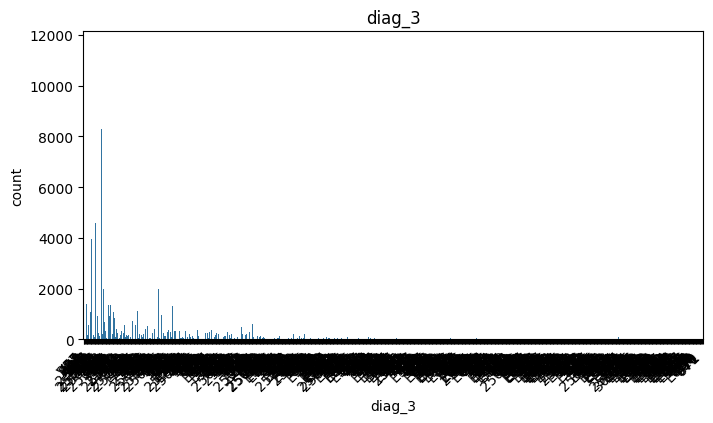

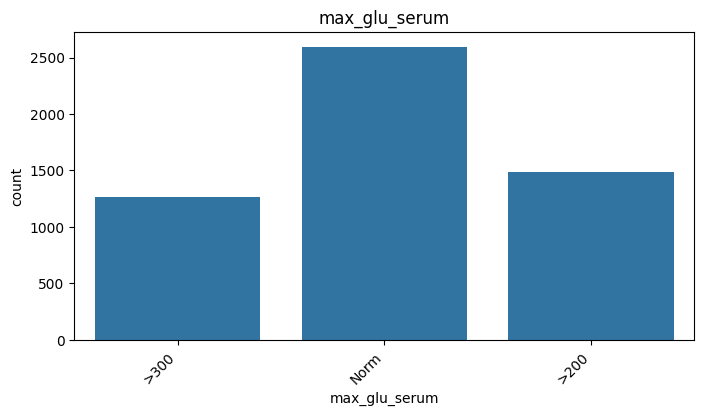

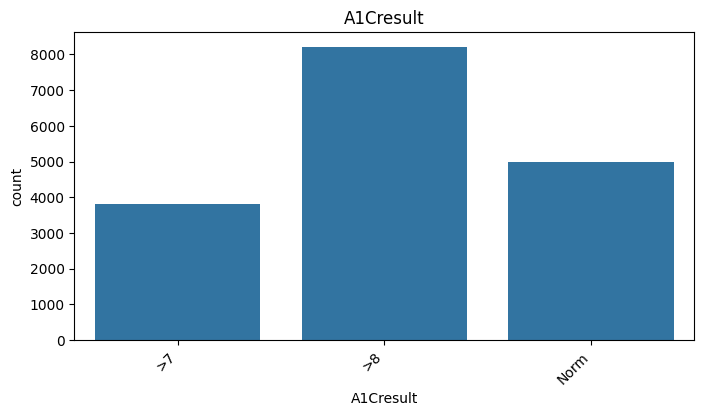

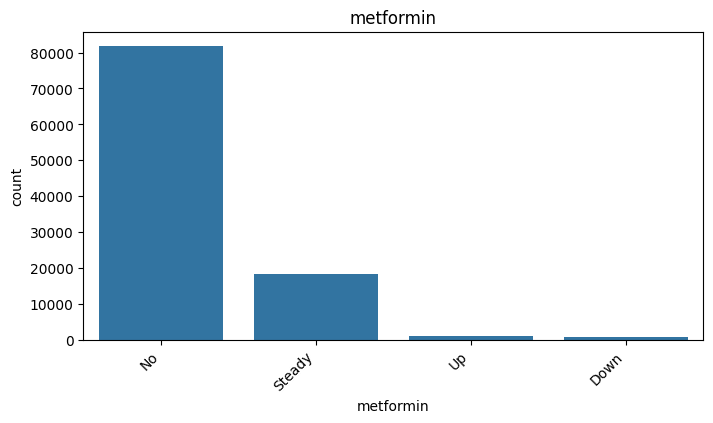

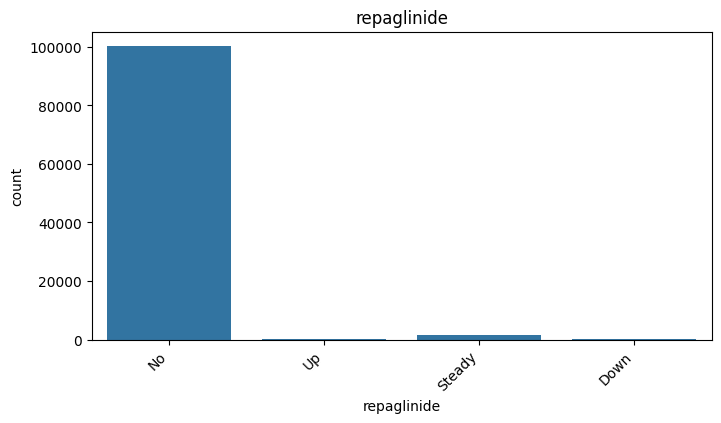

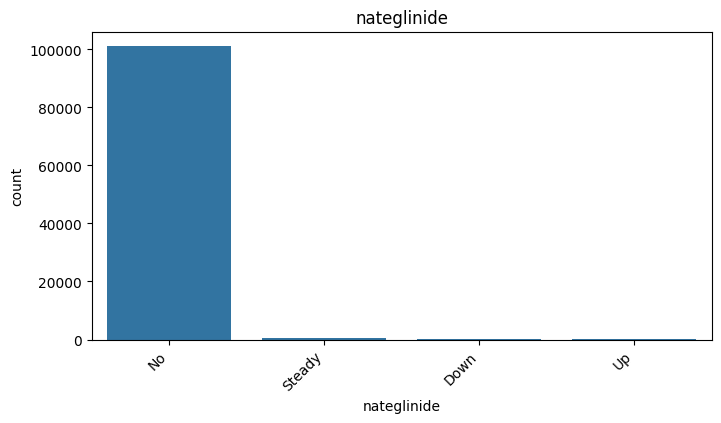

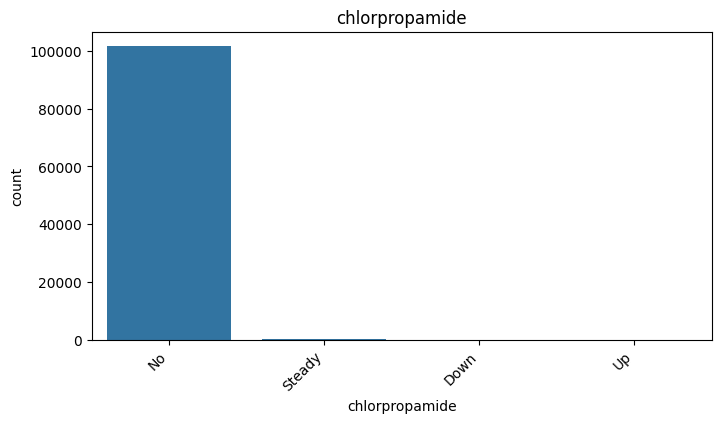

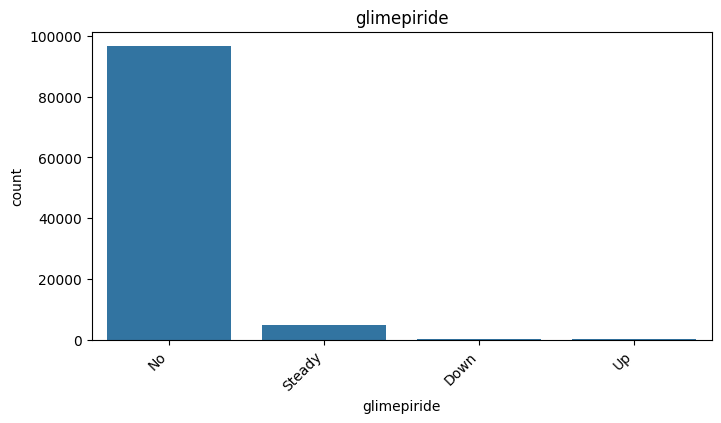

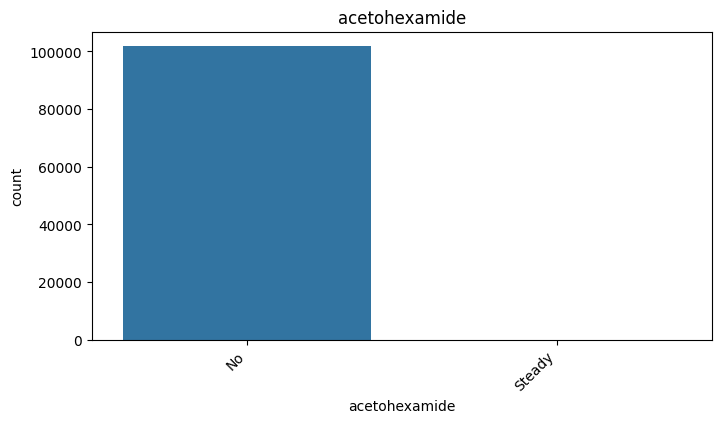

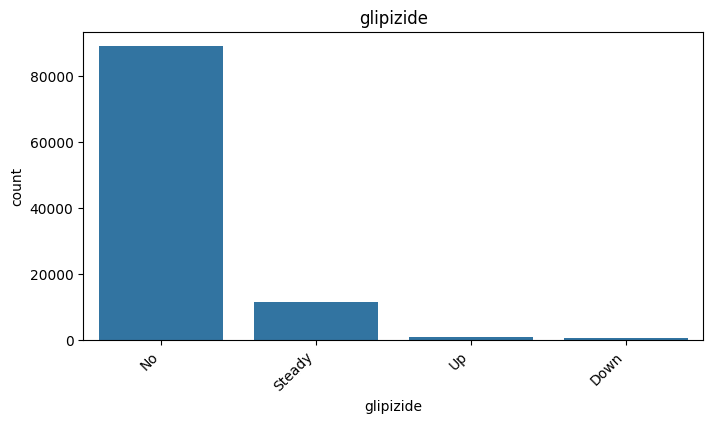

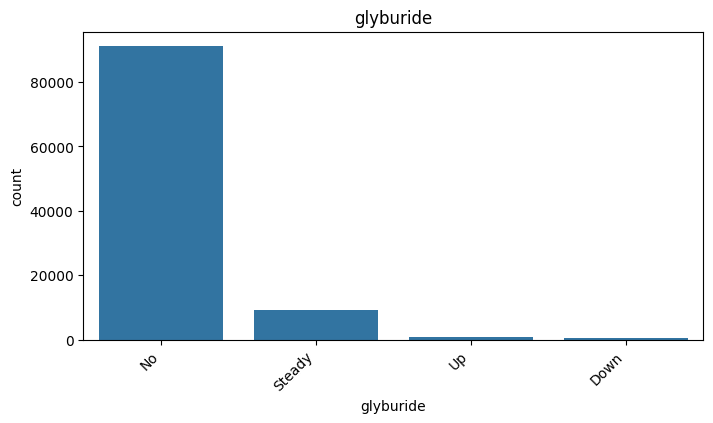

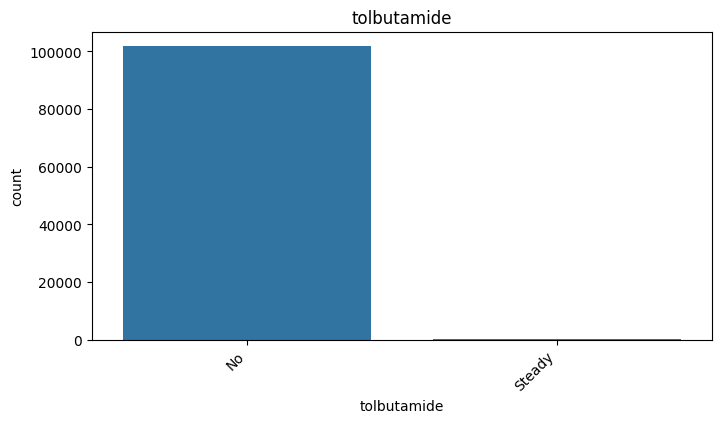

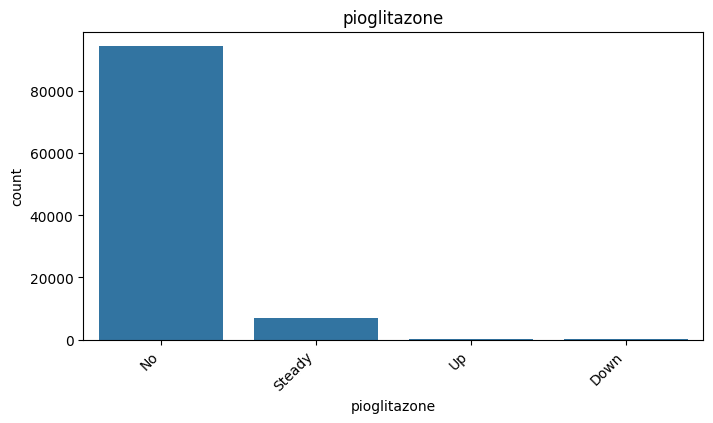

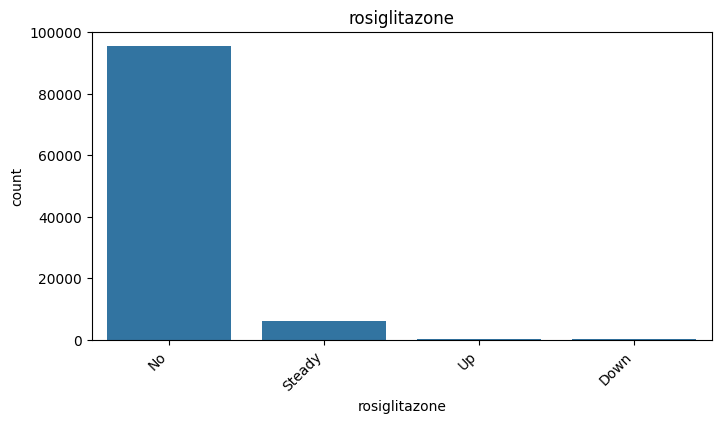

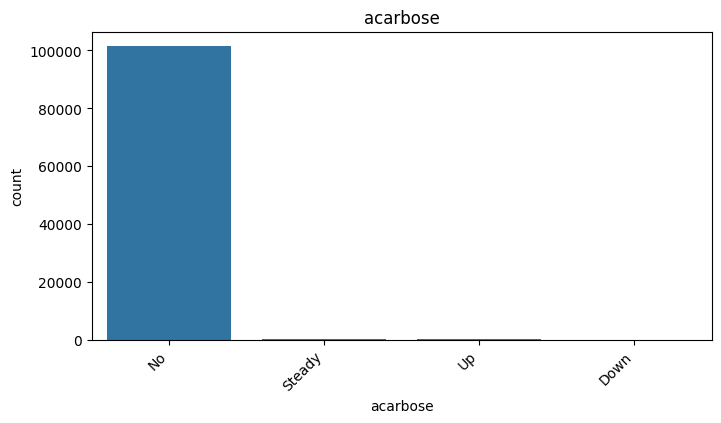

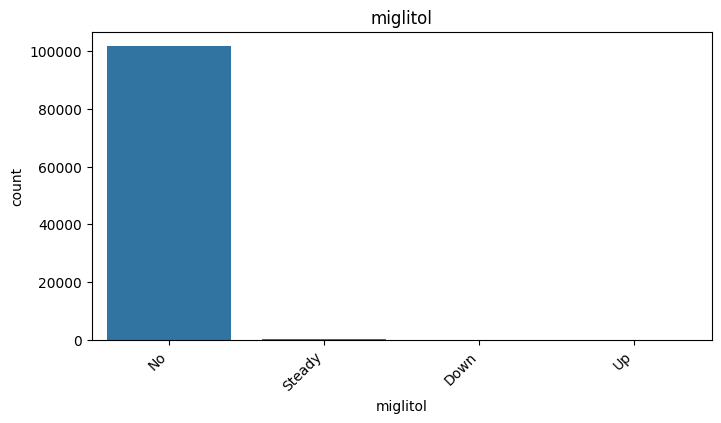

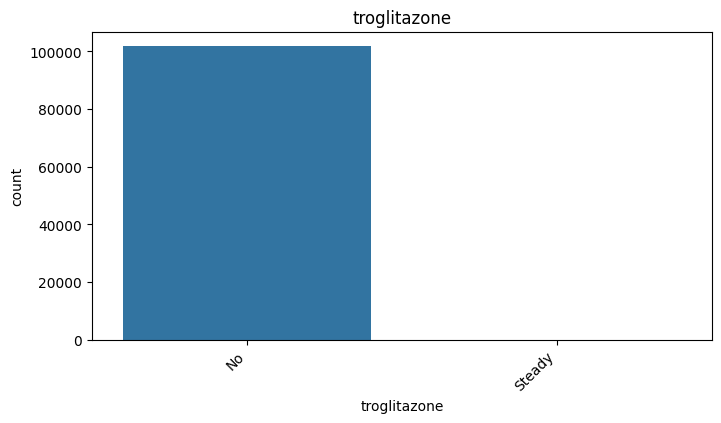

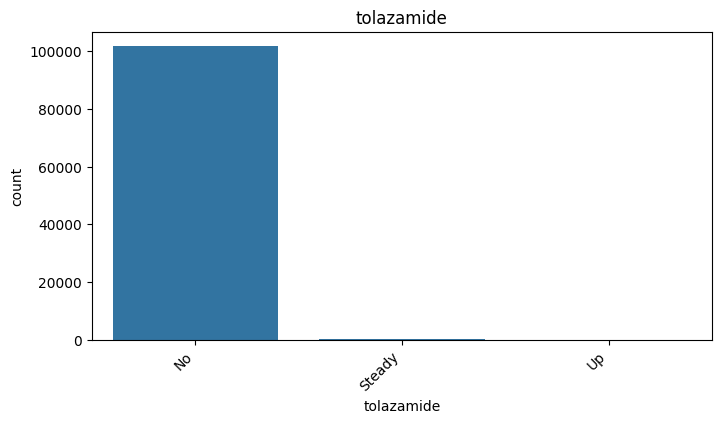

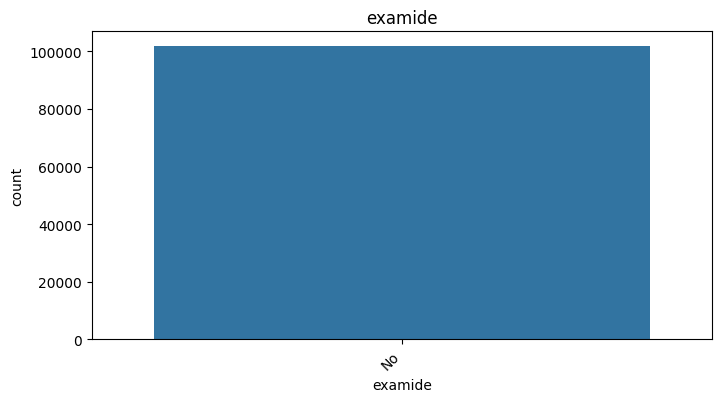

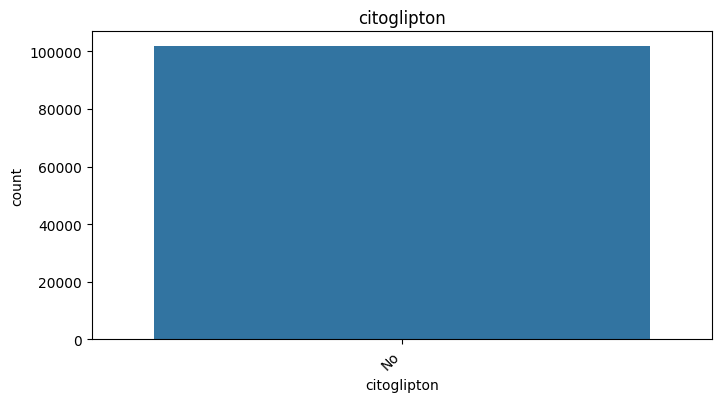

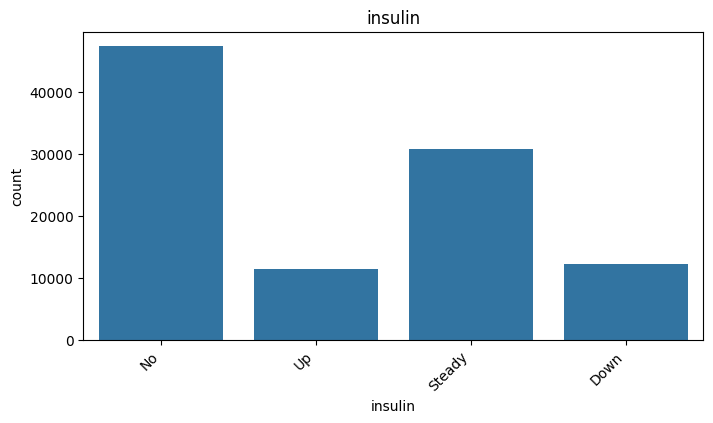

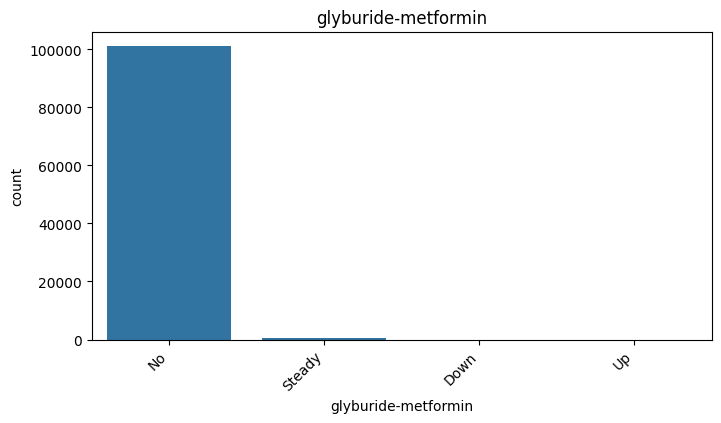

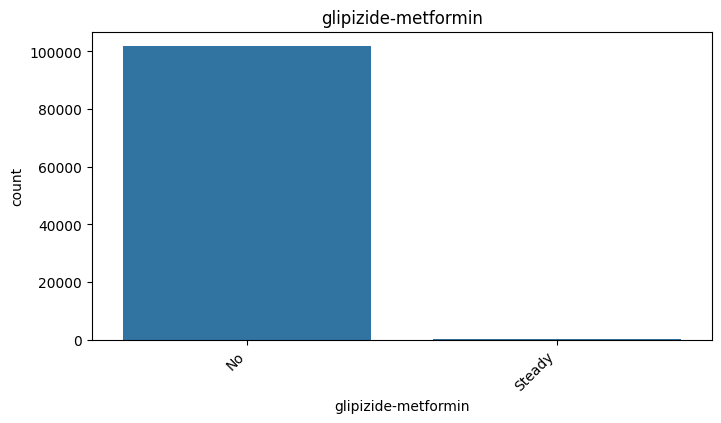

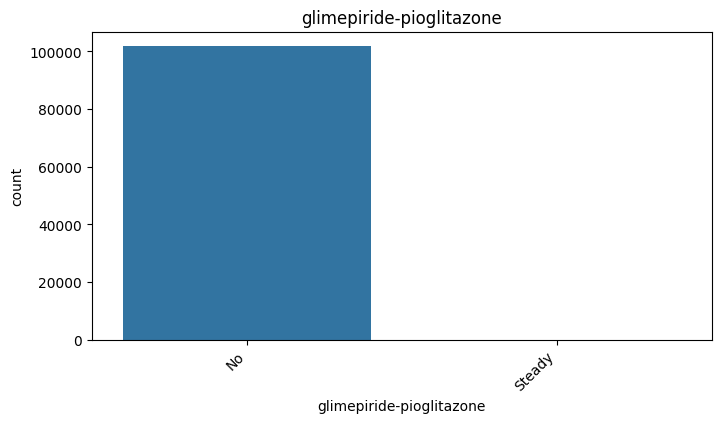

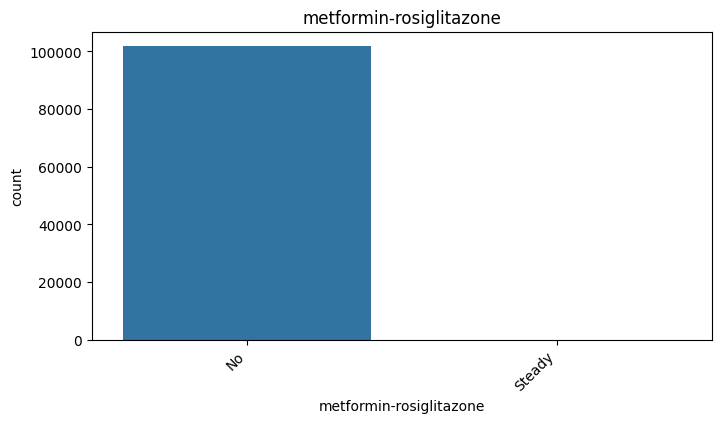

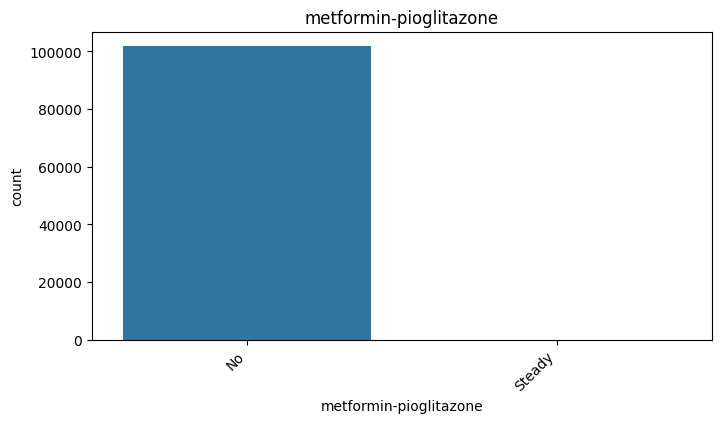

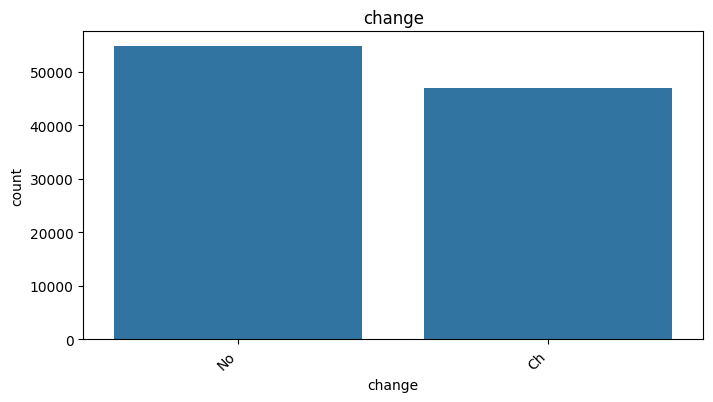

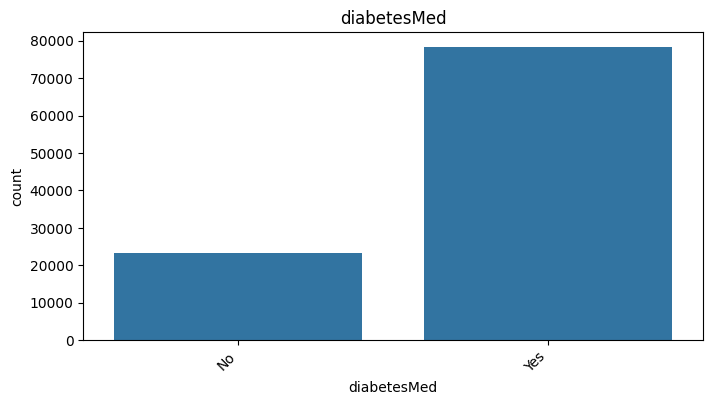

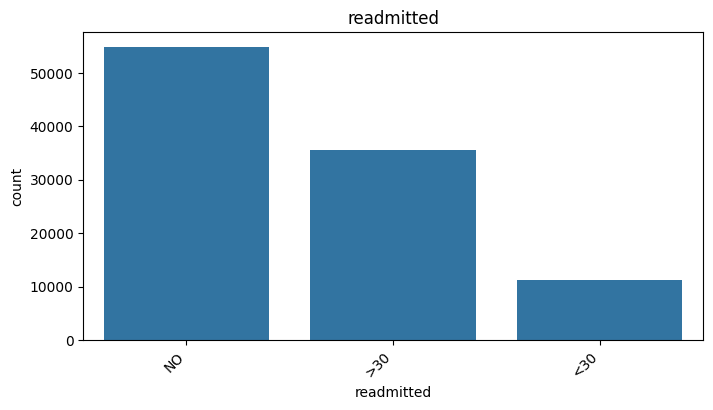

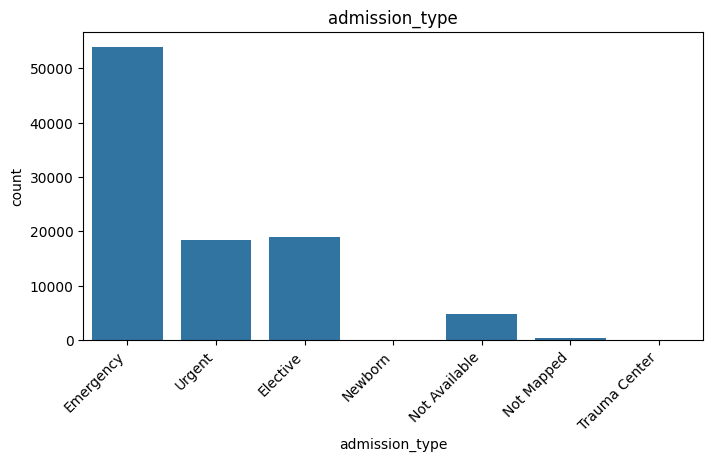

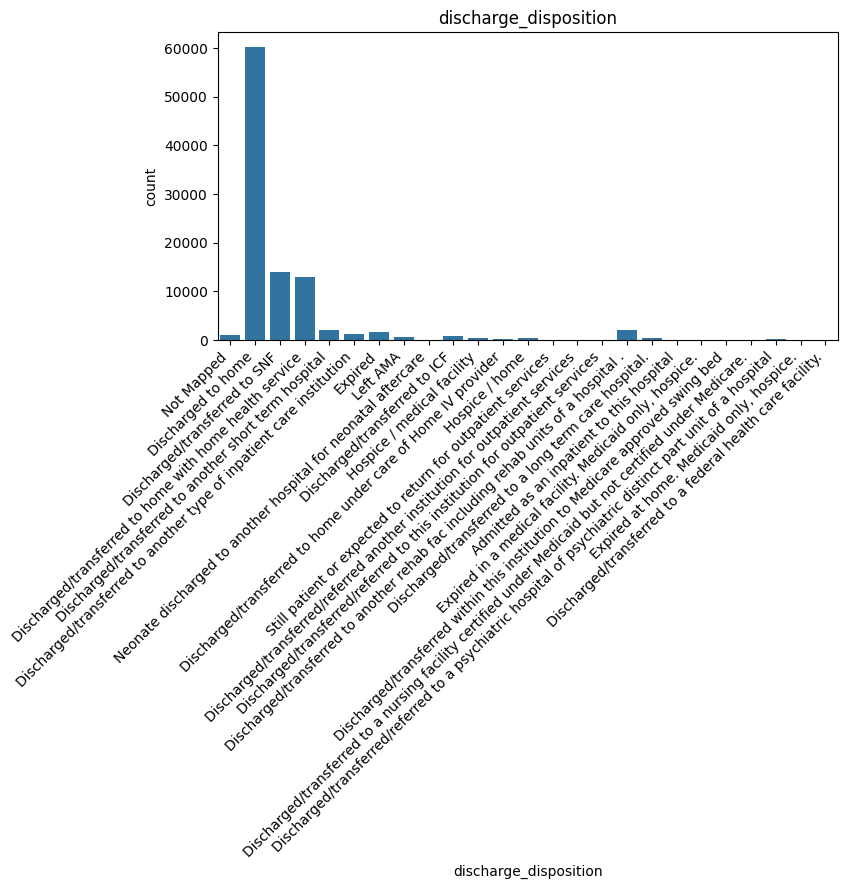

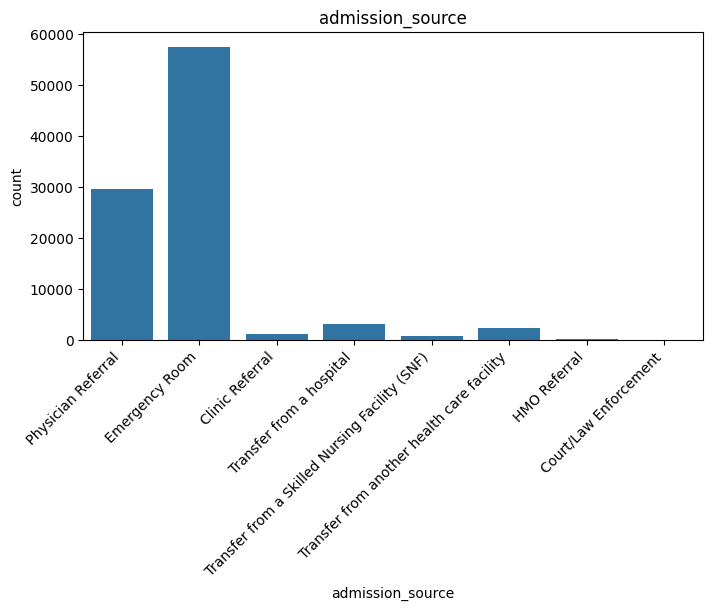

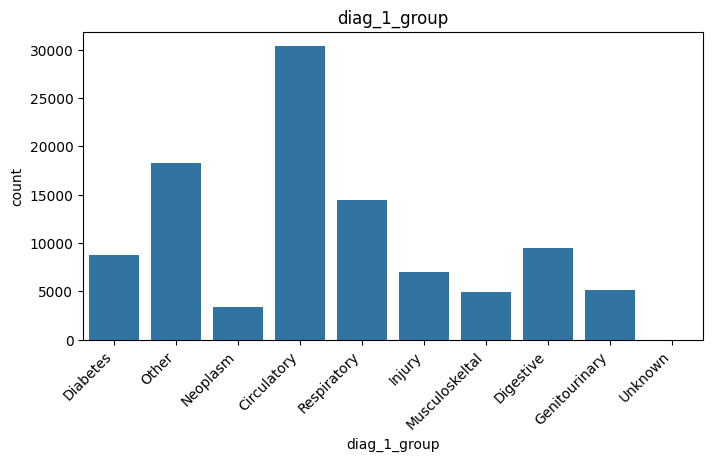

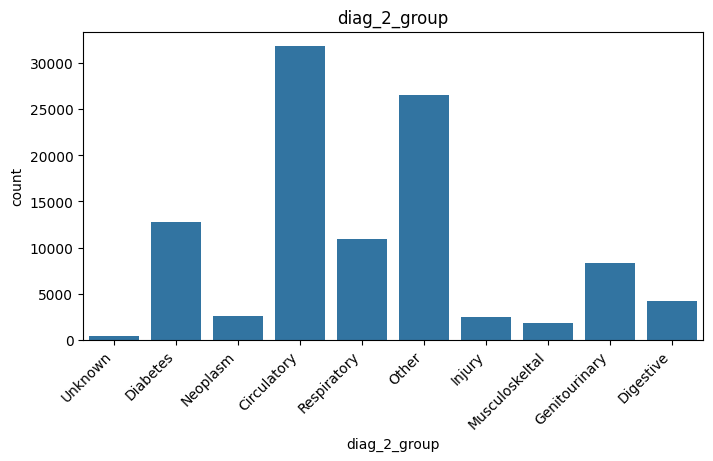

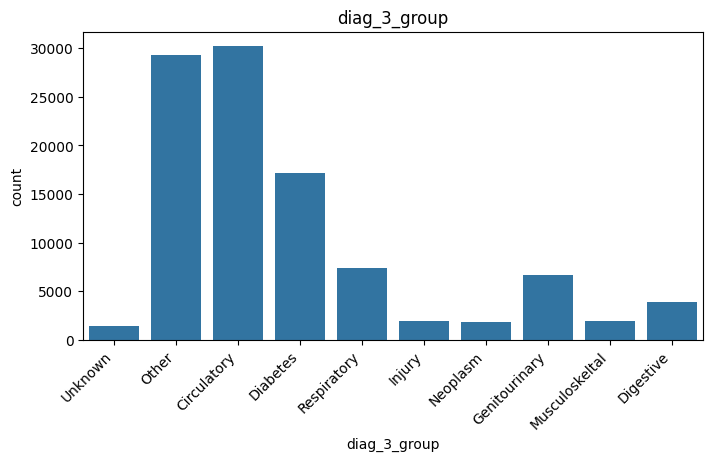

In [54]:
for var in cat_vars:
    plt.figure(figsize=(8,4))
    sns.countplot(data=df, x=var)
    plt.xticks(rotation=45, ha='right')
    plt.title(var)
    plt.show()

Several categorical features exhibit severe class imbalance or high cardinality. Raw diagnosis codes (diag_1–diag_3) are too granular for meaningful visualization, supporting the use of the engineered diagnosis-group features. 

Several medication variables are nearly constant, while insulin and common diabetes medications show greater variation. Weight has substantial missingness, so its observed distribution represents only a small subset of encounters.

A few categories emerge:
- Useful as-is: race, gender, age, insulin, change, diabetesMed, readmitted, admission type, admission source, diagnosis groups.
- Useful but visually messy/high-cardinality: payer_code, medical_specialty, discharge_disposition.
- Raw versions are basically useless to plot: diag_1, diag_2, diag_3. The cardinality is so high that the plots become black carpets. That validates why we engineered the grouped diagnosis variables.
- Nearly constant medication columns: several drugs have virtually everyone in No, such as examide, citoglipton, and some combination therapies. Those may ultimately have zero or near-zero predictive value.
- Weight is deceptive: the plot itself looks okay, but ~97% of weight is missing. The bars only describe the tiny subset with recorded weights. That should be noted.
- medical_specialty is also heavily missing and has tons of categories, so its raw count plot is not particularly readable.
The medication plots are especially informative for preprocessing later. Some variables have real variation — metformin, glipizide, glyburide, pioglitazone, rosiglitazone, and especially insulin. Others are almost constant. Eventually we'll probably consider removing zero-variance or near-zero-variance features, but we don't need to make that modeling decision during EDA.
And the diagnosis-group plots are much better than the raw diagnosis plots, which is a nice justification for that feature engineering.

The medication plots are especially informative for preprocessing later. Some variables have real variation — metformin, glipizide, glyburide, pioglitazone, rosiglitazone, and especially insulin. Others are almost constant. 

Eventually probably consider removing zero-variance or near-zero-variance features, but don't need to make that modeling decision during EDA

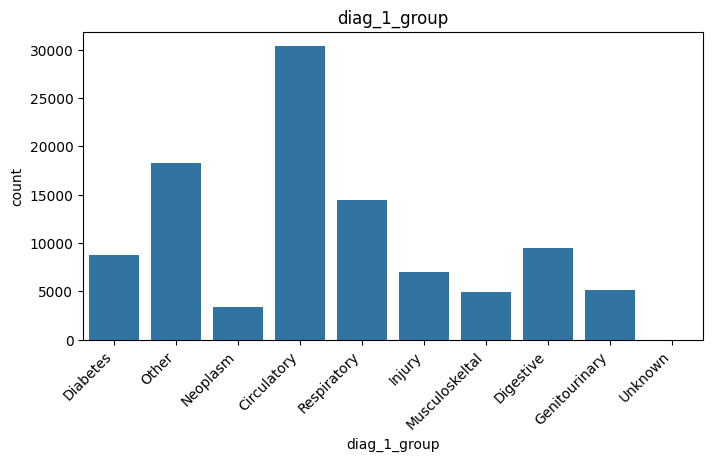

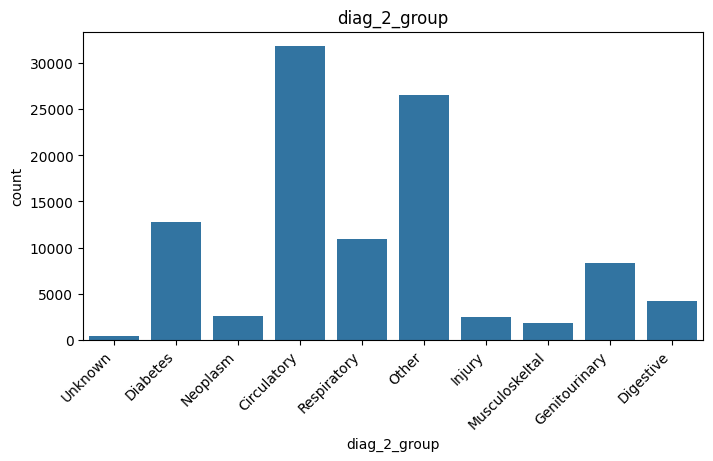

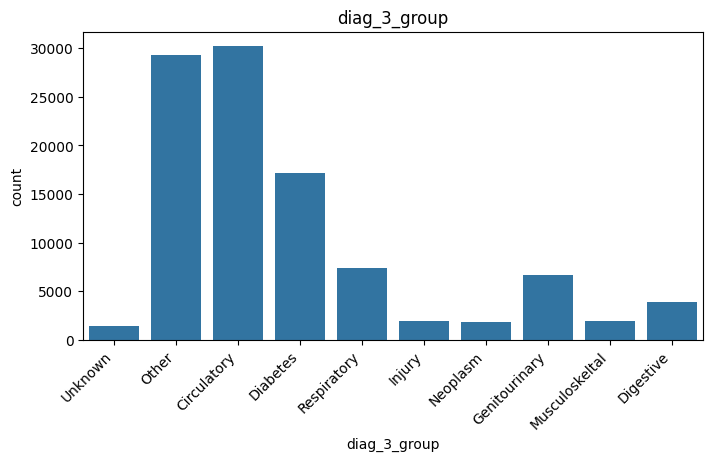

In [55]:
diag_group_vars = ['diag_1_group', 'diag_2_group', 'diag_3_group']

for var in diag_group_vars:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=var)
    plt.xticks(rotation=45, ha="right")
    plt.title(var)
    plt.show()

- diag_1_group: Circulatory is by far the most common primary diagnosis (~30k), then Other (~18k), Respiratory (~14k), Digestive/Diabetes around ~9k. So primary admissions are dominated by circulatory disease.
- diag_2_group: Circulatory is still largest (~32k), but Other (~26k) and Diabetes (~13k) become much more prominent as secondary diagnoses.
- diag_3_group: Circulatory and Other are again ~30k each, but Diabetes jumps to ~17k. So diabetes often appears as a secondary/additional diagnosis rather than the primary reason for admission.

Broad diagnosis grouping substantially improves interpretability compared with the high-cardinality raw ICD-9 codes. 

Circulatory diagnoses are the most common across all three diagnosis positions. 

Diabetes appears more frequently as a secondary or tertiary diagnosis than as the primary diagnosis, suggesting it commonly represents comorbidity rather than the principal reason for admission.

-----------------------------------

## 5. Bivariate Visual EDA


Now we visualize relationships with readmitted_30d.

In [56]:
bivar_num = [
    "time_in_hospital",
    "number_inpatient",
    "number_emergency",
    "number_diagnoses"
]

In [57]:
summary

,mean,count
diag_3_group,,
Circulatory,10.800609,30202
Diabetes,10.567115,17157
Digestive,11.959288,3930
Genitourinary,13.458084,6680
Injury,11.562179,1946
Musculoskeltal,10.652742,1915
Neoplasm,14.224138,1856
Other,11.065224,29299
Respiratory,12.054906,7358


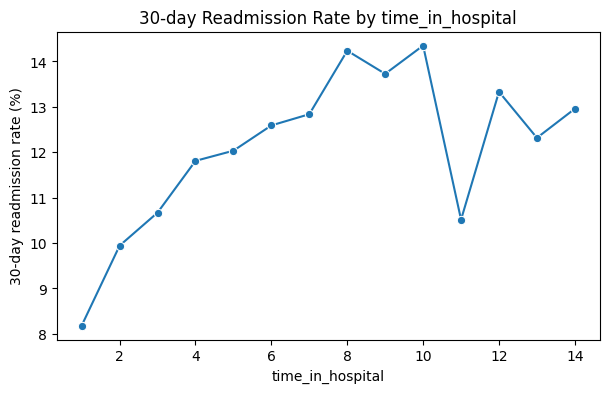

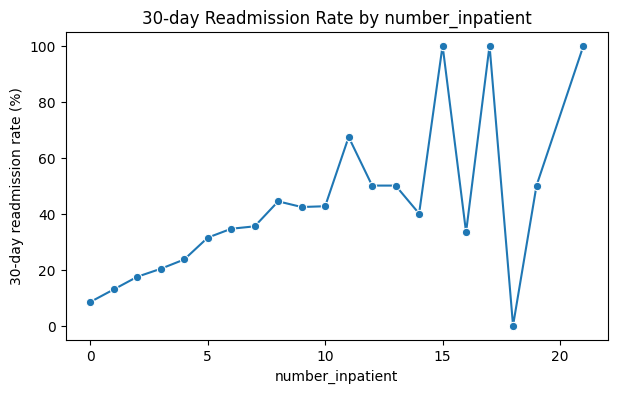

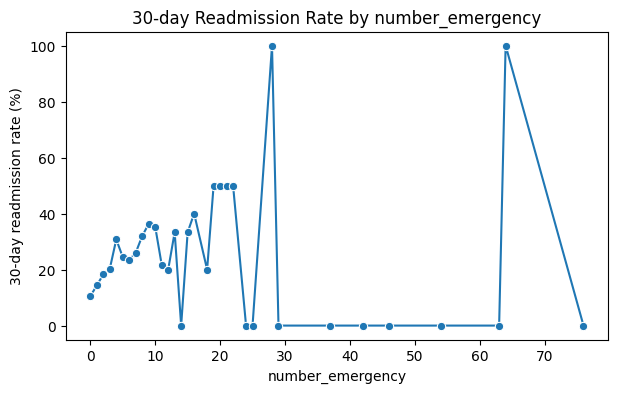

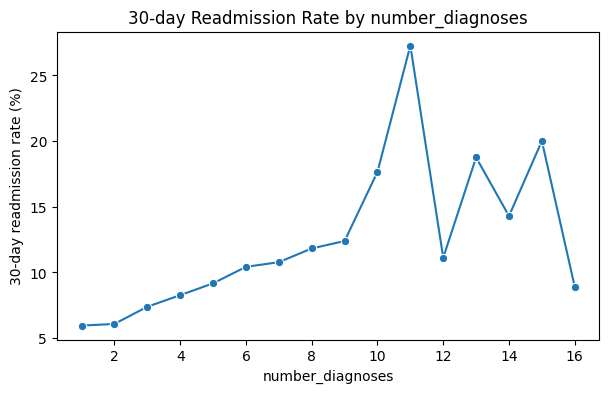

In [58]:
for var in bivar_num:
    summary = df.groupby(var)['readmitted_30d'].mean().reset_index()
    summary['readmitted_30d'] *= 100

    plt.figure(figsize=(7,4))
    sns.lineplot(data=summary, x=var, y='readmitted_30d', marker='o')
    plt.ylabel("30-day readmission rate (%)")
    plt.title(f"30-day Readmission Rate by {var}")
    plt.show()

Remove low count classes from number_inpatient and number_emerg

,number_inpatient,mean,count
0,0,8.437084,67630
1,1,12.924543,19521
2,2,17.433254,7566
3,3,20.287306,3411
4,4,23.612824,1622
5,5,31.403941,812
6,6,34.583333,480
7,7,35.447761,268
8,8,44.370861,151
9,9,42.342342,111


<Axes: xlabel='number_inpatient', ylabel='mean'>

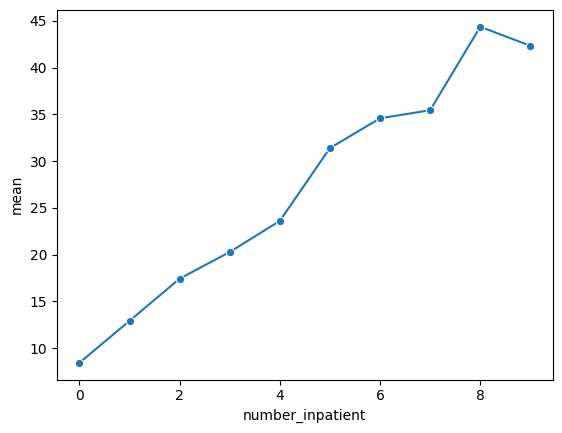

In [59]:
summary = (df.groupby('number_inpatient')['readmitted_30d']
           .agg(['mean', 'count'])
           .reset_index()
)

summary = summary[summary['count'] >= 100]

summary['mean'] *= 100

display(summary)

sns.lineplot(
    data=summary,
    x='number_inpatient',
    y='mean',
    marker='o'
)


   number_emergency       mean  count
0                 0  10.474315  90383
1                 1  14.354566   7677
2                 2  18.266405   2042
3                 3  20.275862    725
4                 4  30.748663    374
5                 5  24.479167    192


<Axes: xlabel='number_emergency', ylabel='mean'>

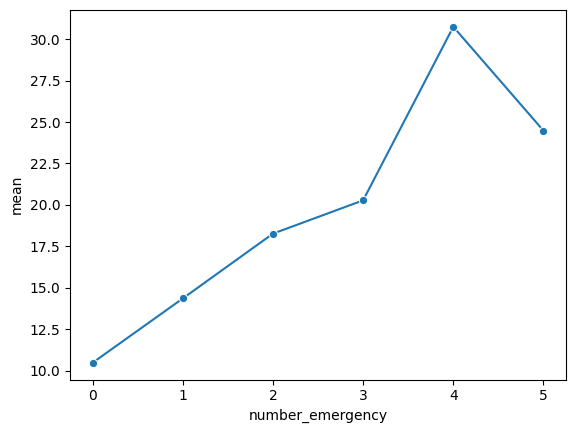

In [60]:
summary = (df.groupby('number_emergency')['readmitted_30d']
           .agg(['mean', 'count'])
           .reset_index()
)

summary = summary[summary['count'] >= 100]

summary['mean'] *= 100

print(summary)

sns.lineplot(
    data=summary,
    x='number_emergency',
    y='mean',
    marker='o'
)

In [61]:
bivar_cat = [
    "discharge_disposition",
    "insulin",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group",
    "admission_type"
]

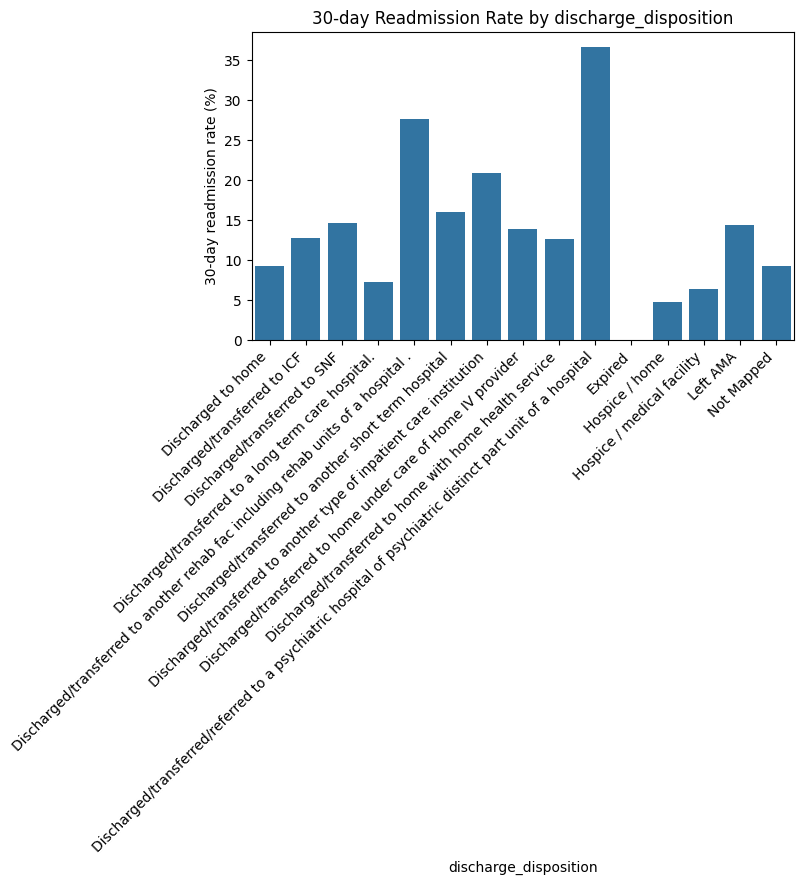

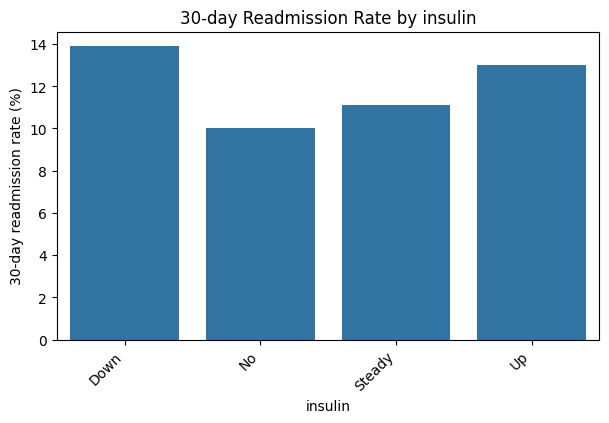

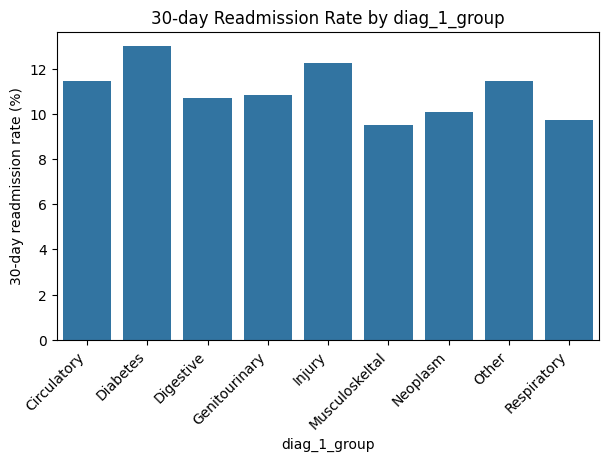

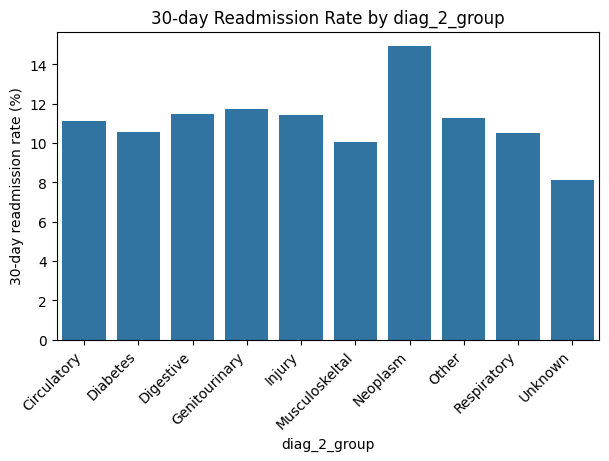

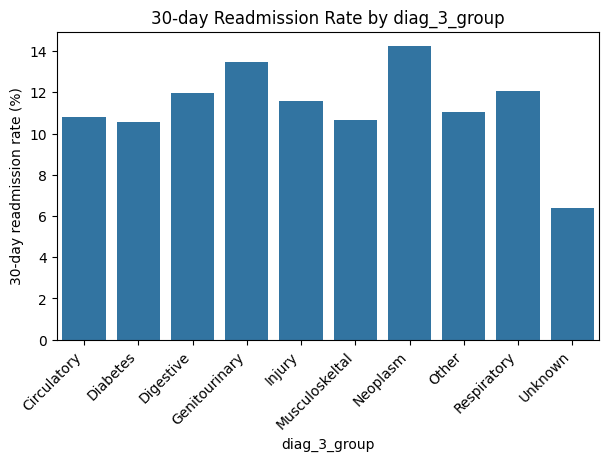

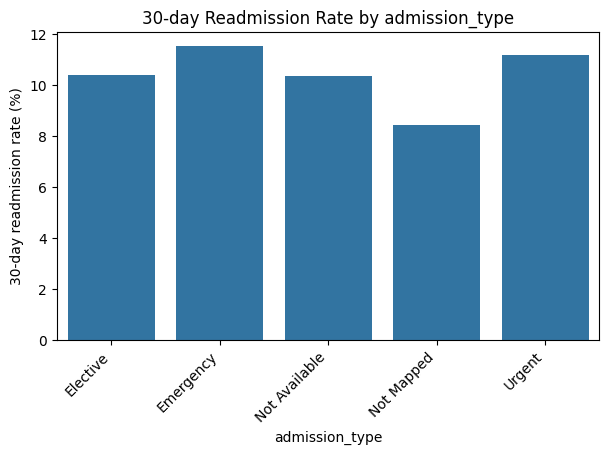

In [62]:
# For each, calculate readmission rate and plot a bar chart.

for var in bivar_cat:
    summary = (
        df.groupby(var)['readmitted_30d']
        .agg(['mean', 'count'])
        .reset_index()
    )

    summary = summary[summary['count'] >= 100]
    summary['mean'] *= 100


    plt.figure(figsize=(7, 4))
    sns.barplot(data=summary, x=var, y='mean')
    
    plt.ylabel("30-day readmission rate (%)")
    plt.title(f"30-day Readmission Rate by {var}")
    plt.xticks(rotation=45, ha='right')
    plt.show()


- Discharge disposition still looks like one of the strongest categorical signals. Rehab / psychiatric / other inpatient-transfer destinations have much higher readmission rates than routine home/hospice-type categories.
- Insulin shows the same pattern we saw numerically: Down and Up are higher than No and Steady.
- diag_1_group has some separation, with Diabetes / Injury somewhat higher and Musculoskeletal / Respiratory lower.
- diag_2_group and diag_3_group also show differences, especially Neoplasm / Genitourinary.
- admission_type is comparatively flat, so probably not a very strong predictor by itself.

Text(0.5, 1.0, '30-day readmission Rate by Discharge Disposition')

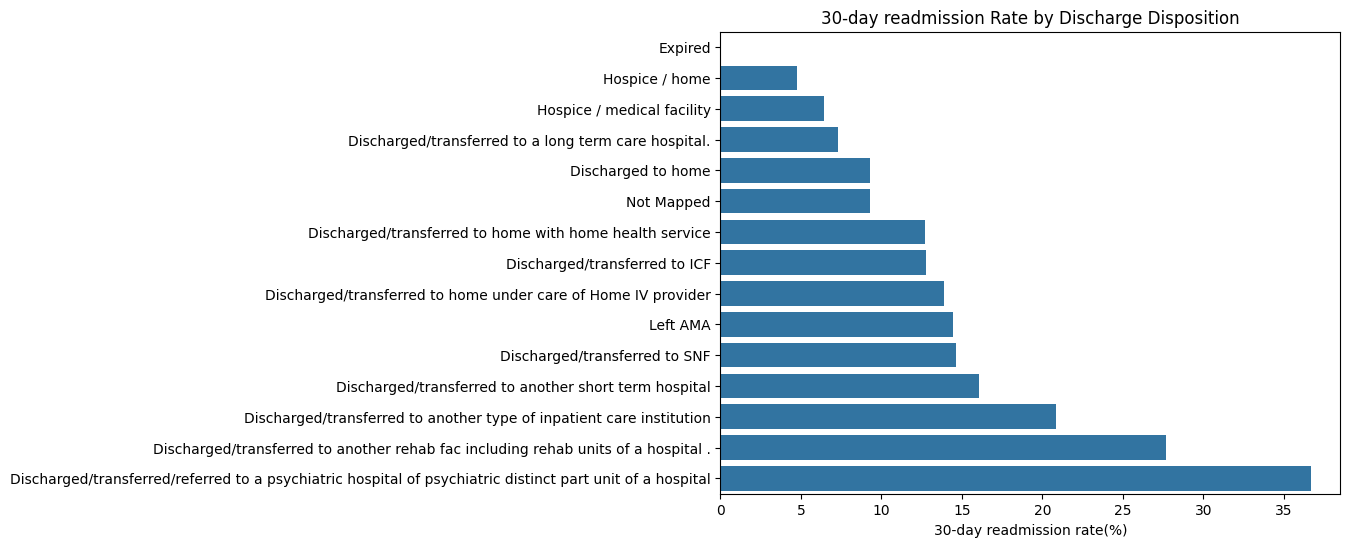

In [63]:
summary = (
    df.groupby('discharge_disposition')['readmitted_30d']
    .agg(['mean','count'])
    .reset_index()
)

summary = summary[summary['count'] >= 100]
summary['mean'] *= 100
summary = summary.sort_values('mean')

plt.figure(figsize=(8,6))
sns.barplot(
    data=summary, 
    y='discharge_disposition', 
    x='mean',
)

plt.xlabel('30-day readmission rate(%)')
plt.ylabel("")
plt.title('30-day readmission Rate by Discharge Disposition')

-------------------------------------------

## 6. Multivariate Non-Visual EDA


In [64]:
num_vars

['time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses']

In [65]:
multivar_num = num_vars + ['readmitted_30d']
multivar_num

['time_in_hospital',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'number_diagnoses',
 'readmitted_30d']

In [66]:
corr = df[multivar_num].corr()
corr

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_30d
time_in_hospital,1.000000,0.318450,0.191472,0.466135,-0.008916,-0.009681,0.073623,0.220186,0.044199
num_lab_procedures,0.318450,1.000000,0.058066,0.268161,-0.007602,-0.002279,0.039231,0.152773,0.020364
num_procedures,0.191472,0.058066,1.000000,0.385767,-0.024819,-0.038179,-0.066236,0.073734,-0.012227
num_medications,0.466135,0.268161,0.385767,1.000000,0.045197,0.013180,0.064194,0.261526,0.038432
number_outpatient,-0.008916,-0.007602,-0.024819,0.045197,1.000000,0.091459,0.107338,0.094152,0.018893
number_emergency,-0.009681,-0.002279,-0.038179,0.013180,0.091459,1.000000,0.266559,0.055539,0.060747
number_inpatient,0.073623,0.039231,-0.066236,0.064194,0.107338,0.266559,1.000000,0.104710,0.165147
number_diagnoses,0.220186,0.152773,0.073734,0.261526,0.094152,0.055539,0.104710,1.000000,0.049524
readmitted_30d,0.044199,0.020364,-0.012227,0.038432,0.018893,0.060747,0.165147,0.049524,1.000000


In [67]:
# age * prior admissions
df['inpatient_group'] = pd.cut(
    df['number_inpatient'],
    bins=[-1, 0, 1, 2, 4, float('inf')],
    labels=[
    "0 prior admissions",
    "1 prior",
    "2 prior",
    "3-4 prior",
    "5+ prior"
]
)

pivot_age_inpatient = pd.pivot_table(
    df,
    values='readmitted_30d',
    index='age',
    columns='inpatient_group',
    aggfunc='mean',
    observed=True
) * 100

pivot_age_inpatient = pivot_age_inpatient.round(1)

pivot_age_inpatient

inpatient_group,0 prior admissions,1 prior,2 prior,3-4 prior,5+ prior
age,,,,,
[0-10),1.3,9.1,0.0,NaN,NaN
[10-20),3.7,7.2,17.9,13.3,20.0
[20-30),5.5,17.4,29.1,24.5,51.6
[30-40),6.4,13.2,23.8,27.4,40.4
[40-50),7.0,12.6,17.7,21.5,39.6
[50-60),6.8,11.8,17.0,19.7,38.7
[60-70),8.5,13.2,17.0,22.1,35.2
[70-80),9.6,13.3,16.9,20.5,33.7
[80-90),10.1,13.2,16.9,21.9,23.8


In [68]:
# insulin * primary diagnoses group

pivot_diag_insulin = pd.pivot_table(
    df,
    values='readmitted_30d',
    index='diag_1_group',
    columns='insulin',
    aggfunc='mean'
) * 100

pivot_diag_insulin = pivot_diag_insulin.round(1)

pivot_diag_insulin

insulin,Down,No,Steady,Up
diag_1_group,,,,
Circulatory,14.6,10.3,11.5,13.5
Diabetes,14.5,13.0,11.9,13.2
Digestive,12.9,9.6,11.2,12.5
Genitourinary,16.3,8.9,11.1,12.3
Injury,14.3,10.7,13.2,14.1
Musculoskeltal,15.8,7.8,10.6,12.1
Neoplasm,13.5,8.8,10.1,13.4
Other,12.8,10.8,10.8,15.1
Respiratory,12.3,9.0,9.7,9.8


In [69]:
interaction = (
    df.groupby(["diag_1_group", "discharge_disposition"])["readmitted_30d"]
      .agg(["mean", "count"])
      .reset_index()
)

interaction["readmission_rate"] = (interaction["mean"] * 100).round(1)

interaction = (
    interaction[interaction["count"] >= 50]
    .sort_values("readmission_rate", ascending=False)
)

interaction[
    ["diag_1_group", "discharge_disposition", "readmission_rate", "count"]
]

,diag_1_group,discharge_disposition,readmission_rate,count
149,Other,Discharged/transferred/referred to a psychiatr...,42.0,50
143,Other,Discharged/transferred to another short term h...,40.4,371
28,Diabetes,Discharged/transferred to another rehab fac in...,31.2,125
6,Circulatory,Discharged/transferred to another rehab fac in...,31.0,658
86,Injury,Discharged/transferred to another rehab fac in...,27.6,475
...,...,...,...,...
56,Digestive,Expired,0.0,94
130,Neoplasm,Expired,0.0,134
151,Other,Expired,0.0,283
173,Respiratory,Expired,0.0,348


- < 20: usually way too unstable to interpret
- 20–50: still pretty noisy
- 50–100: usable with caution
- 100+: much more comfortable for descriptive EDA

Cells with fewer than 50 encounters were suppressed because subgroup readmission rates were unstable.


In [70]:
high_risk_interactions =interaction[
    (interaction['readmission_rate'] >= 15) &
    (interaction['count'] >= 50)
].sort_values(
    ['readmission_rate', 'count'],
    ascending=False
)
high_risk_interactions = high_risk_interactions[
    ["diag_1_group", "discharge_disposition", "readmission_rate", "count"]
]

high_risk_interactions

,diag_1_group,discharge_disposition,readmission_rate,count
149,Other,Discharged/transferred/referred to a psychiatr...,42.0,50
143,Other,Discharged/transferred to another short term h...,40.4,371
28,Diabetes,Discharged/transferred to another rehab fac in...,31.2,125
6,Circulatory,Discharged/transferred to another rehab fac in...,31.0,658
86,Injury,Discharged/transferred to another rehab fac in...,27.6,475
30,Diabetes,Discharged/transferred to another type of inpa...,27.2,92
106,Musculoskeltal,Discharged/transferred to another rehab fac in...,25.2,345
8,Circulatory,Discharged/transferred to another type of inpa...,23.8,323
142,Other,Discharged/transferred to another rehab fac in...,23.7,190
88,Injury,Discharged/transferred to another type of inpa...,21.4,154


High 30-day readmission rates were concentrated among patients discharged to rehabilitation, skilled nursing, other inpatient care institutions, and short-term hospitals.  
These patterns appeared across multiple primary diagnosis groups and remained present in subgroups with substantial encounter counts, suggesting that discharge disposition captures important patient complexity and transition-of-care risk beyond diagnosis alone.

----------------------------------------------------

## 7. Multivariate Visual EDA


<function matplotlib.pyplot.show(close=None, block=None)>

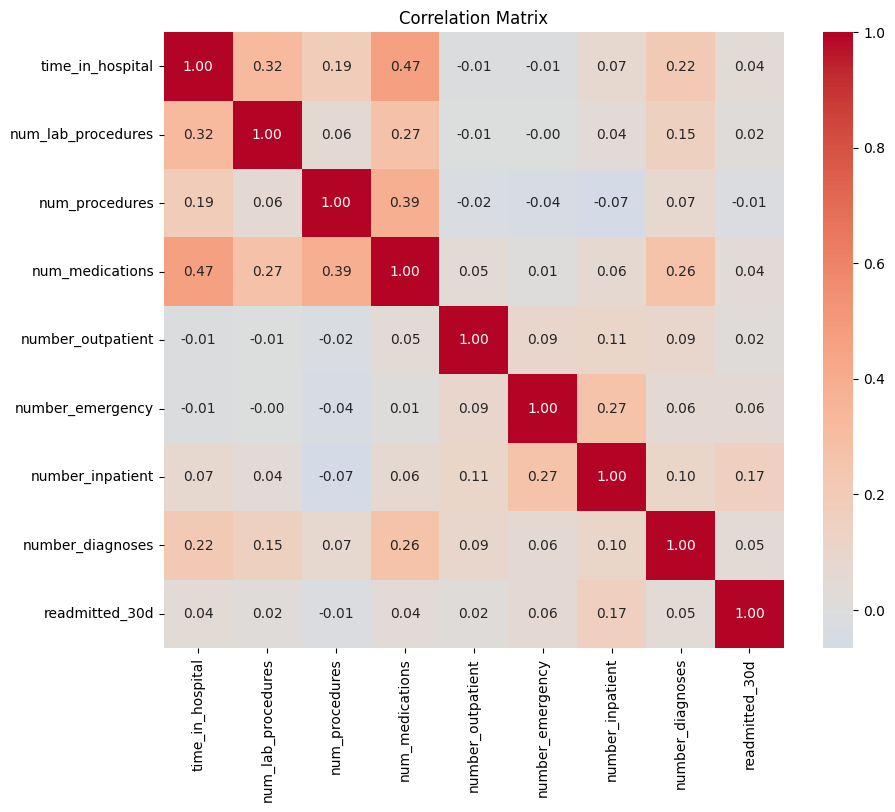

In [71]:
# Correlation matrix

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    center=0

)

plt.title('Correlation Matrix')
plt.show

- |r| < 0.7 → usually not a concern
- |r| ≈ 0.7–0.8 → start paying attention
- |r| > 0.8 → often considered high multicollinearity
- |r| > 0.9 → very high / likely redundant

The numeric predictors are mostly only weak-to-moderately correlated with one another, so there is limited redundancy. 

Prior inpatient utilization has the strongest simple correlation with 30-day readmission, but several relationships identified earlier are likely non-linear and therefore not fully captured by Pearson correlation.

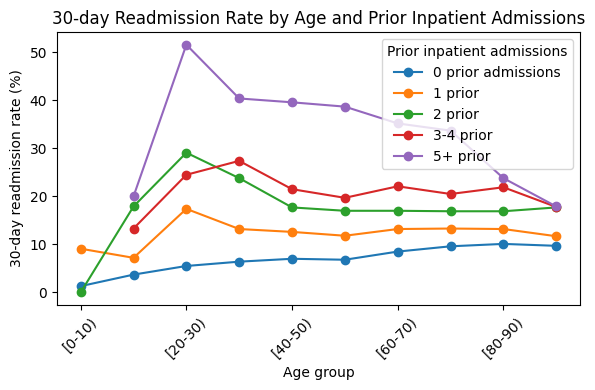

In [72]:
# age x primary intpatient admissions
pivot_age_inpatient.plot(
    kind='line',
    marker='o',
    figsize=(6, 4)
)

plt.ylabel("30-day readmission rate (%)")
plt.xlabel("Age group")
plt.title("30-day Readmission Rate by Age and Prior Inpatient Admissions")
plt.legend(title="Prior inpatient admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


prior admissions remain important across age groups 

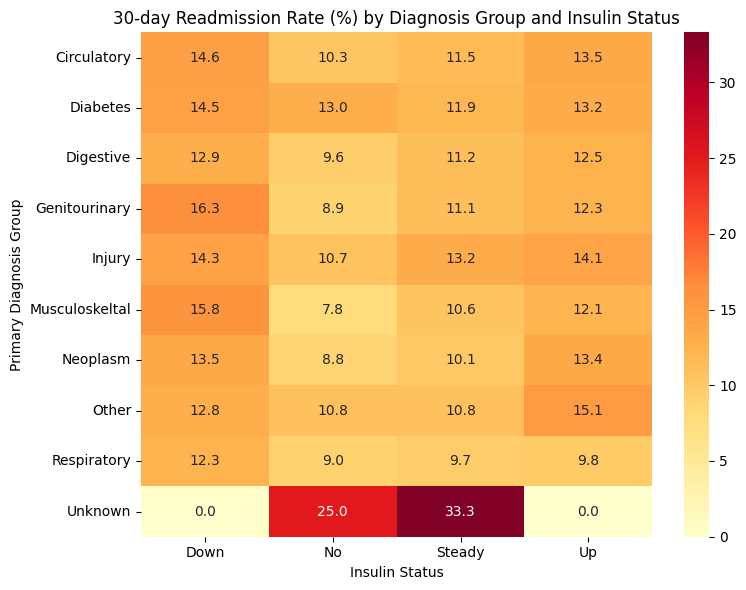

In [73]:
# primary diagnoses group * insulin

plt.figure(figsize=(8,6))

sns.heatmap(
    pivot_diag_insulin,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd'
)

plt.title("30-day Readmission Rate (%) by Diagnosis Group and Insulin Status")
plt.xlabel("Insulin Status")
plt.ylabel("Primary Diagnosis Group")
plt.tight_layout()
plt.show()


insulin status interacts somewhat with diagnosis group rather than having exactly the same effect everywhere

-------------------------------------------------------------

## EDA Summary and Implications for Preprocessing

The exploratory analysis identified several patterns that will directly inform preprocessing and model development.

### Target distribution
The 30-day readmission target is imbalanced. Approximately 11% of encounters were followed by readmission within 30 days, while the large majority were not. Because of this, accuracy alone will not be an appropriate model evaluation metric. Stratified splitting and metrics such as recall, precision, F1, ROC-AUC, PR-AUC, and calibration will be more informative.

### Missing data
Missingness varied substantially across features. `weight` was missing for nearly all encounters and is therefore a strong candidate for exclusion. `medical_specialty` and `payer_code` also contained substantial missingness, while `race` and the diagnosis fields had much smaller amounts of missing data. Missing diagnosis values were retained as an `Unknown` category in the grouped diagnosis features rather than deleting encounters.

### Numeric feature distributions
Several utilization and treatment variables were strongly right-skewed or zero-inflated. In particular, `number_inpatient`, `number_emergency`, and `number_outpatient` were dominated by zero values, with relatively few encounters at the upper end of the distributions. `num_procedures` was similarly concentrated at low values, while `num_medications` and `time_in_hospital` were right-skewed.

`number_diagnoses` showed a very large concentration at 9 diagnoses. The dataset documentation defines this feature as the number of diagnoses entered into the system but does not explain this spike, suggesting that it may reflect a structural or administrative feature of the source data rather than a natural clinical distribution. The feature should therefore be interpreted cautiously.

### Stronger bivariate relationships with readmission
Prior inpatient utilization showed the clearest relationship with 30-day readmission. Readmission rates rose substantially as `number_inpatient` increased. This pattern remained present after stratifying by age, suggesting that the association is not simply explained by older patients having more prior admissions.

`number_emergency`, `time_in_hospital`, and `number_diagnoses` also showed generally increasing readmission rates across their more common values, although the relationships were weaker than for prior inpatient utilization.

Discharge disposition was one of the strongest categorical signals. Patients transferred to rehabilitation facilities, skilled nursing facilities, other inpatient institutions, short-term hospitals, and similar post-acute settings generally had higher readmission rates than patients discharged directly home.

Insulin status also showed meaningful differences. Patients whose insulin dose was increased or decreased generally had higher readmission rates than patients receiving no insulin or a steady dose.

### Diagnosis features
The raw `diag_1`, `diag_2`, and `diag_3` ICD-9 variables had very high cardinality and were difficult to interpret directly. They were therefore grouped into broader clinically meaningful categories using the diagnosis grouping defined in the original study.

The grouped diagnosis features were much more interpretable. Circulatory diagnoses were the most common across all three diagnosis positions. Diabetes appeared more frequently as a secondary or tertiary diagnosis than as the primary diagnosis, consistent with its role as a common comorbidity.

Readmission rates differed across diagnosis groups. The relationship also varied depending on whether the diagnosis was primary, secondary, or tertiary, supporting the decision to retain `diag_1_group`, `diag_2_group`, and `diag_3_group` as separate features rather than collapsing them into a single diagnosis variable.

### Multivariate findings
The numeric correlation matrix showed only weak-to-moderate relationships among the predictors. The strongest predictor-predictor correlation was between `time_in_hospital` and `num_medications`, at approximately 0.47. No pairwise correlations approached conventional thresholds associated with severe multicollinearity.

Simple Pearson correlations with the target were generally modest. `number_inpatient` had the strongest positive correlation with 30-day readmission at approximately 0.17. However, several variables showed clear monotonic or nonlinear patterns in grouped analyses despite weak Pearson correlations, demonstrating that Pearson correlation alone does not capture their full predictive value.

The interaction between age and prior inpatient utilization showed that higher prior inpatient use was associated with higher readmission rates across most age groups. This suggests that prior inpatient utilization is a robust risk marker rather than an effect driven by a particular age group.

The interaction between primary diagnosis group and insulin status showed that the association between insulin status and readmission varied across diagnosis groups. Insulin dose increases and decreases generally showed higher readmission rates than no insulin use, but the magnitude of the difference was not identical across diagnoses.

The interaction between primary diagnosis group and discharge disposition also showed that higher readmission rates were concentrated among patients discharged to rehabilitation, skilled nursing, other inpatient institutions, short-term hospitals, and psychiatric facilities. These patterns occurred across several diagnosis groups, suggesting that discharge disposition captures additional patient complexity and transition-of-care risk beyond diagnosis alone.

### Implications for preprocessing
The EDA suggests the following preprocessing decisions:

- Exclude identifier fields such as `encounter_id` from the model.
- Retain `patient_nbr` temporarily for train/test splitting because the same patient may appear in multiple encounters.
- Avoid a naive row-level random split that could place encounters from the same patient in both training and test sets.
- Drop `weight` because of extreme missingness.
- Evaluate whether `medical_specialty` and `payer_code` should be retained with an `Unknown` category, grouped into broader categories, or excluded.
- Replace raw admission, discharge, and admission-source ID variables with their readable mapped categorical versions.
- Use the engineered `diag_1_group`, `diag_2_group`, and `diag_3_group` variables rather than the high-cardinality raw ICD-9 diagnosis codes for the initial model.
- Retain important utilization variables such as `number_inpatient`, `number_emergency`, `number_outpatient`, `time_in_hospital`, and `number_diagnoses`.
- Retain categorical variables such as age, race, gender, admission type, discharge disposition, admission source, insulin status, A1C result, glucose result, and medication-related variables that show meaningful variation.
- Identify and remove zero-variance or near-zero-variance medication variables before modeling.
- Encode categorical variables appropriately, likely using one-hot encoding for the baseline model.
- Consider scaling numeric variables for linear models, while recognizing that tree-based models will not require scaling.
- Preserve the class imbalance in evaluation and use metrics appropriate for an imbalanced binary classification problem.

------------------------------------------------------------------------

# Preprocessing

## Modeling roadmap
1. Build the modeling dataframe
   - drop obvious non-features
   - keep patient_nbr only for splitting
   - keep engineered diagnosis groups
   - decide what to do with payer_code, medical_specialty, near-constant meds
2. Create patient-level train/test split
   - same patient cannot appear in both train and test
   - preserve target balance as much as reasonably possible
3. Separate X and y
   - X = predictors
   - y = readmitted_30d
4. Define preprocessing
   - numeric columns
   - categorical columns
   - impute where needed
   - one-hot encode categoricals
   - scale numeric features for logistic regression
5. Build baseline logistic regression
   - first plain model
   - evaluate properly
6. Evaluate
   - confusion matrix
   - precision
   - recall
   - F1
   - ROC-AUC
   - PR-AUC
   - maybe calibration
7. Handle class imbalance
   Compare:
   - plain logistic regression
   - class_weight="balanced"
   - SMOTE on training data only
8. Try stronger models
   - Random Forest
   - gradient boosting / XGBoost
9. Compare models
   - performance
   - minority-class recall
   - precision-recall tradeoff
   - calibration
10. Interpret the best models
    - logistic coefficients
    - feature importance
    - SHAP later if useful
11. Error analysis
    - false negatives
    - false positives
    - which patient groups are being missed
12. Final model choice
- choose based on useful clinical performance, not just highest AUC

-----------------------------------------------------------------

### Step 1: build the modeling dataframe.

In [74]:
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted',
 'readmitted_30d',
 'admission_type',
 'discharge_disposition',
 'admission_source',
 'diag_1_group',
 'diag_2_group',
 'diag_3_group

do not drop patient_nbr yet, because we need it for the patient-level split.

do not drop payer_code, medical_specialty, or the medication columns yet. Those need one more deliberate check before decision.

In [75]:
model_df = df.copy()

drop_cols = [
    "encounter_id",                 # identifier
    "weight",                       # extreme missingness
    "admission_type_id",            # replaced by readable mapped version
    "discharge_disposition_id",     # replaced by readable mapped version
    "admission_source_id",          # replaced by readable mapped version
    "diag_1",                       # replaced by grouped diagnosis
    "diag_2",
    "diag_3",
    "readmitted",                   # original 3-class target, not a predictor
    "inpatient_group"               # engineered for EDA only; duplicates number_inpatient
]

model_df = model_df.drop(columns=drop_cols)

In [76]:
# quantify the categorical columns that are basically constant or extremely sparse:
# gives us number of distinct values and # proportion occupied by the most common category
# Then we can make a justified decision about which medication columns are near-zero-variance instead of eyeballing them.

object_cols = model_df.select_dtypes(include='object').columns

for col in object_cols:
    print(
        col,
        model_df[col].nunique(dropna=False),
        model_df[col].value_counts(normalize=True, dropna=False).iloc[0]
    )

race 6 0.7477841322249081
gender 3 0.5375862272271682
age 10 0.25615628009354796
payer_code 18 0.395574160328597
medical_specialty 73 0.49082208203132677
max_glu_serum 4 0.9474677200636755
A1Cresult 4 0.8327732248491637
metformin 4 0.8035886248845391
repaglinide 4 0.9848770709274217
nateglinide 4 0.9930919953619087
chlorpropamide 4 0.9991549240414284
glimepiride 4 0.9489908220820313
acetohexamide 2 0.9999901735353655
glipizide 4 0.8753414696460508
glyburide 4 0.8953481516420022
tolbutamide 2 0.9997739913134053
pioglitazone 4 0.9279916671579899
rosiglitazone 4 0.9374545526010651
acarbose 4 0.9969734488925575
miglitol 4 0.999626594343887
troglitazone 2 0.9999705206060964
tolazamide 3 0.9996167678792524
examide 1 1.0
citoglipton 1 1.0
insulin 4 0.46560737377906175
glyburide-metformin 4 0.993062515968005
glipizide-metformin 2 0.9998722559597508
glimepiride-pioglitazone 2 0.9999901735353655
metformin-rosiglitazone 2 0.9999803470707309
metformin-pioglitazone 2 0.9999901735353655
change 2 0.5

- 'examide' and 'citoglipton' have only one unique value, so they contain literally no predictive information. Drop them.
- A bunch of other medication variables are extremely sparse, but your printed proportions are rounded. A displayed 1.0 might mean 99.6%, not literally 100%, so I would not drop them blindly yet.
- 'medical_specialty' has 73 categories plus heavy missingness, so that one will need special handling.
- 'payer_code' has 18 categories and isn't nearly as extreme as expected. wouldn't automatically drop it.
- 'max_glu_serum' and 'A1Cresult' are highly dominated by missing/one category, but clinically meaningful enough that wouldn't throw them away solely because of that.
- 'insulin', 'change', 'diabetesMed', the admission variables, and diagnosis groups clearly have enough variation to retain.

In [77]:
model_df = model_df.drop(columns=[
    'examide',
    'citoglipton'
])

In [78]:
sparse_meds = [
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "acetohexamide",
    "tolbutamide",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

for col in sparse_meds:
    print(f'\n{col}')
    print(model_df[col].value_counts(dropna=False))


repaglinide
repaglinide
No        100227
Steady      1384
Up           110
Down          45
Name: count, dtype: int64

nateglinide
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

chlorpropamide
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

acetohexamide
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

tolbutamide
tolbutamide
No        101743
Steady        23
Name: count, dtype: int64

acarbose
acarbose
No        101458
Steady       295
Up            10
Down           3
Name: count, dtype: int64

miglitol
miglitol
No        101728
Steady        31
Down           5
Up             2
Name: count, dtype: int64

troglitazone
troglitazone
No        101763
Steady         3
Name: count, dtype: int64

tolazamide
tolazamide
No        101727
Steady        38
Up             1
Name: count, dtype: int64

glyburide-metformin
glyburide-metformin
No       

we will drop medication features where >99.9% of encounters are the same category.

In [79]:
rare_med_cols = [
    "chlorpropamide",
    "acetohexamide",
    "tolbutamide",
    "miglitol",
    "troglitazone",
    "tolazamide",
    # "examide", already removed
    # "citoglipton", already removed
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

model_df = model_df.drop(columns=rare_med_cols)

In [80]:
# medical_specality has 73 categories and 49% missing. lets investigate
model_df['medical_specialty'].value_counts(dropna=False)

medical_specialty
NaN                       49949
InternalMedicine          14635
Emergency/Trauma           7565
Family/GeneralPractice     7440
Cardiology                 5352
                          ...  
Proctology                    1
Speech                        1
SportsMedicine                1
Perinatology                  1
Neurophysiology               1
Name: count, Length: 73, dtype: int64

In [81]:
model_df['medical_specialty'] = model_df['medical_specialty'].fillna('Unknown')

specialty_counts = model_df['medical_specialty'].value_counts()

common_specialities = specialty_counts[
    specialty_counts >= 100
].index

model_df['medical_specialty'] = model_df['medical_specialty'].where(
    model_df['medical_specialty'].isin(common_specialities),
    'Other'
)

In [82]:
model_df['medical_specialty'].value_counts()

medical_specialty
Unknown                              49949
InternalMedicine                     14635
Emergency/Trauma                      7565
Family/GeneralPractice                7440
Cardiology                            5352
Surgery-General                       3099
Nephrology                            1613
Orthopedics                           1400
Orthopedics-Reconstructive            1233
Radiologist                           1140
Other                                  925
Pulmonology                            871
Psychiatry                             854
Urology                                685
ObstetricsandGynecology                671
Surgery-Cardiovascular/Thoracic        652
Gastroenterology                       564
Surgery-Vascular                       533
Surgery-Neuro                          468
PhysicalMedicineandRehabilitation      391
Oncology                               348
Pediatrics                             254
Hematology/Oncology                 

In [83]:
model_df['payer_code'].value_counts(dropna=False)

payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64

we will keep payer code 

In [84]:
model_df['payer_code'] = model_df['payer_code'].fillna('Unknown')

payer_counts = model_df['payer_code'].value_counts()

common_payers = payer_counts[
    payer_counts >= 100
].index

model_df['payer_code'] = model_df['payer_code'].where(
    model_df['payer_code'].isin(common_payers),
    'Other'
)

In [85]:
model_df['payer_code'].value_counts(dropna=False)

payer_code
Unknown    40256
MC         32439
HM          6274
SP          5007
BC          4655
MD          3532
CP          2533
UN          2448
CM          1937
OG          1033
PO           592
DM           549
Other        230
CH           146
WC           135
Name: count, dtype: int64

In [86]:
model_df.isna().sum().sort_values(ascending=False)

max_glu_serum            96420
A1Cresult                84748
admission_source          7094
admission_type            5291
discharge_disposition     3691
race                      2273
patient_nbr                  0
gender                       0
age                          0
num_procedures               0
time_in_hospital             0
payer_code                   0
number_emergency             0
number_outpatient            0
number_diagnoses             0
number_inpatient             0
metformin                    0
num_medications              0
medical_specialty            0
num_lab_procedures           0
glimepiride                  0
nateglinide                  0
repaglinide                  0
glipizide                    0
acarbose                     0
glyburide                    0
pioglitazone                 0
rosiglitazone                0
change                       0
glyburide-metformin          0
insulin                      0
readmitted_30d               0
diabetes

In [87]:
(model_df.isna().mean() * 100).sort_values(ascending=False)

max_glu_serum            94.746772
A1Cresult                83.277322
admission_source          6.970894
admission_type            5.199182
discharge_disposition     3.626948
race                      2.233555
patient_nbr               0.000000
gender                    0.000000
age                       0.000000
num_procedures            0.000000
time_in_hospital          0.000000
payer_code                0.000000
number_emergency          0.000000
number_outpatient         0.000000
number_diagnoses          0.000000
number_inpatient          0.000000
metformin                 0.000000
num_medications           0.000000
medical_specialty         0.000000
num_lab_procedures        0.000000
glimepiride               0.000000
nateglinide               0.000000
repaglinide               0.000000
glipizide                 0.000000
acarbose                  0.000000
glyburide                 0.000000
pioglitazone              0.000000
rosiglitazone             0.000000
change              

In [89]:
missing_summary = pd.DataFrame({
    'missing_count': model_df.isna().sum(),
    'missing_percent': model_df.isna().mean() * 100
})

missing_summary = (
    missing_summary
    .sort_values('missing_count', ascending=False)
    .round({'missing_percent': 2})
)

missing_summary

,missing_count,missing_percent
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
admission_source,7094,6.97
admission_type,5291,5.20
discharge_disposition,3691,3.63
race,2273,2.23
patient_nbr,0,0.00
gender,0,0.00
age,0,0.00
num_procedures,0,0.00


- max_glu_serum: 95% missing, drop
- A1Cresult: same idea, fill missing as "Unknown".
- admission_source, admission_type, discharge_disposition: fill missing as "Unknown" rather than dropping rows.
- race: fill missing as "Unknown".

In [90]:
model_df = model_df.drop(columns=[
    'max_glu_serum',
    'A1Cresult'
])

missing_cat_cols = [
    "admission_source",
    "admission_type",
    "discharge_disposition",
    "race"
]

model_df[missing_cat_cols] = model_df[missing_cat_cols].fillna('Unknown')

model_df.isna().sum().sort_values(ascending=False)

patient_nbr              0
race                     0
gender                   0
age                      0
time_in_hospital         0
payer_code               0
medical_specialty        0
num_lab_procedures       0
num_procedures           0
num_medications          0
number_outpatient        0
number_emergency         0
number_inpatient         0
number_diagnoses         0
metformin                0
repaglinide              0
nateglinide              0
glimepiride              0
glipizide                0
glyburide                0
pioglitazone             0
rosiglitazone            0
acarbose                 0
insulin                  0
glyburide-metformin      0
change                   0
diabetesMed              0
readmitted_30d           0
admission_type           0
discharge_disposition    0
admission_source         0
diag_1_group             0
diag_2_group             0
diag_3_group             0
dtype: int64

`max_glu_serum` and `A1Cresult` were excluded from the baseline model because approximately 95% and 83% of their values were missing, respectively. 

Their potential predictive value can be evaluated separately in later model experiments.

## Final check before train test split

In [ ]:


# Confirm:
# - no remaining missing values
# - readmitted_30d is still present
# - patient_nbr is still present for grouping
# - readmitted is gone
# - raw diag_1, diag_2, diag_3 are gone
# - raw admission/discharge/source IDs are gone
# - weight, max_glu_serum, A1Cresult are gone
# - rare medication columns we decided to drop are gone

print(model_df.shape)

print("\nMissing values:")
print(model_df.isna().sum()[model_df.isna().sum() > 0])

print("\nTarget distribution:")
print(model_df["readmitted_30d"].value_counts(normalize=True))

print("\nPatient count:")
print(model_df["patient_nbr"].nunique())

print("\nColumns:")
print(model_df.columns.tolist())

(101766, 34)

Missing values:
Series([], dtype: int64)

Target distribution:
readmitted_30d
0    0.888401
1    0.111599
Name: proportion, dtype: float64

Patient count:
71518

Columns:
['patient_nbr', 'race', 'gender', 'age', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed', 'readmitted_30d', 'admission_type', 'discharge_disposition', 'admission_source', 'diag_1_group', 'diag_2_group', 'diag_3_group']


----------------------------------------------------

# Train test Split

- should not use a normal train_test_split directly on rows, because the same patient can have multiple encounters.
- Because one patient can have multiple encounters, we want all encounters from a given patient to land entirely in either train or test.
- The cleanest first pass is GroupShuffleSplit


In [93]:
from sklearn.model_selection import GroupShuffleSplit

X = model_df.drop(columns='readmitted_30d')
y = model_df['readmitted_30d']
groups = model_df['patient_nbr']

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

In [ ]:
X_train = X_train.drop(columns=['patient_nbr'])
X_test = X_test.drop(columns=['patient_nbr'])

In [94]:
print('Train shape: X_train.shape')
print('Test shape: X_test.shape')

print('\nTrain target:')
print(y_train.value_counts(normalize=True))

print('\nTest target:')
print(y_test.value_counts(normalize=True))

Train shape: X_train.shape
Test shape: X_test.shape

Train target:
readmitted_30d
0    0.887199
1    0.112801
Name: proportion, dtype: float64

Test target:
readmitted_30d
0    0.893267
1    0.106733
Name: proportion, dtype: float64


GSS did not stratify (preserve proportions) the target.  
Thus, lets check StratifiedGroupKFold

- Since we want roughly an 80/20 holdout, we can use 5 folds and take one fold as test

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

X = model_df.drop(columns=["readmitted_30d"])
y = model_df["readmitted_30d"]
groups = model_df["patient_nbr"]

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    sgkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

In [96]:
print('Train shape: X_train.shape')
print('Test shape: X_test.shape')

print('\nTrain target:')
print(y_train.value_counts(normalize=True))

print('\nTest target:')
print(y_test.value_counts(normalize=True))

Train shape: X_train.shape
Test shape: X_test.shape

Train target:
readmitted_30d
0    0.888407
1    0.111593
Name: proportion, dtype: float64

Test target:
readmitted_30d
0    0.888376
1    0.111624
Name: proportion, dtype: float64


In [98]:
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

overlap = train_patients.intersection(test_patients)

print('Patients in train:', len(train_patients))
print('Patients in test:', len(test_patients))
print('Patients in overlap', len(overlap))

Patients in train: 57231
Patients in test: 14287
Patients in overlap 0


we have both things we wanted:
- patient leakage prevented
- target prevalence preserved at ~11.16% in both sets

--------------------------------------------------

## Preprocessing features 

- separate numeric vs categorical columns
- scale numeric features for logistic regression
- one-hot encode categorical features
- wrap both in a ColumnTransformer

In [ ]:
# separate numeric vs categorical columns

numeric_cols = X_train.select_dtypes(include='number').columns.tolist()

categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

Print('Numeric columns: ', numeric_cols)

Print('Numeric columns: ', categorical_cols)